# Trabalho 5 — Privacidade Diferencial Local com *Generalized Randomized Response* (GRR)

**Privacidade de Dados — 2026.2** · Equipe: *(preencher)*

Um agregador quer responder 10 consultas de contagem sobre **Idade** e **Salário** sem nunca observar os dados originais. Cada usuário perturba localmente o seu par (idade, salário) com o GRR, que satisfaz ε-LDP, e envia apenas o *report*. O servidor estima as contagens a partir dos reports. Comparamos duas estratégias:

* **E1** — GRR sobre o domínio conjunto Idade × Salário (k = 74 · 2 = 148);
* **E2** — GRR com a idade agrupada em *bins* (k = k<sub>B</sub> · 2), com a largura do bin escolhida e justificada a partir do workload.

**Divisão na equipe.** Parte A (*nome*): Seções 0–8, 9.4–9.8 e 10. Parte B (*nome*): Seções 9.1–9.3 (tabelas e figuras obrigatórias dos resultados), relatório e slides.

**Organização.** Todo o código está neste único notebook. Os módulos pedidos no enunciado (GRR, consultas, estratégias e avaliação) correspondem às seções 2 a 5.

| Seção | Conteúdo |
|---|---|
| 0 | Configuração: parâmetros do protocolo, sementes, utilitários |
| 1 | Dados |
| 2 | **Módulo GRR**: lado do cliente (perturbação) e lado do servidor (estimação) |
| 3 | **Módulo Consultas**: workload Q1–Q10 |
| 4 | **Módulo Estratégias**: E1 e E2 (idade em bins) |
| 5 | **Módulo Avaliação**: MAE, execução do protocolo, erro teórico |
| 6 | Testes de corretude |
| 7 | Escolha do tamanho do bin (análise do workload) |
| 8 | Experimentos |
| 9 | Resultados: tabelas e figuras (9.1–9.3: Parte B) |
| 10 | Análise: respostas às perguntas do enunciado |

**Como executar:** deixe `dados_censo.csv` na mesma pasta do notebook e execute todas as células (*Run All*). Leva menos de 1 minuto e requer `numpy`, `pandas` e `matplotlib`. As tabelas (CSV, Markdown e LaTeX) e as figuras (PNG e PDF) são gravadas em `resultados/`.

## 0. Configuração

Parâmetros do protocolo experimental (Seção 5 do enunciado): ε ∈ {0,5; 1; 2; 4}, estratégias E1 e E2, R = 10 repetições por configuração.

**Sementes (reprodutibilidade).** A repetição r ∈ {0, …, 9} usa o gerador `np.random.default_rng(2026 + r)`, isto é, as sementes 2026, 2027, …, 2035. As **mesmas** sementes valem para todas as configurações (estratégia × ε), o que torna as comparações entre configurações pareadas. Rodar o notebook de novo reproduz exatamente todos os números.

In [37]:
from __future__ import annotations

import math
import time
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import display

# ------------------------------ Protocolo experimental ------------------------------
ARQUIVO_DADOS = Path("dados_censo.csv")
EPSILONS = [0.5, 1.0, 2.0, 4.0]          # orçamento total de privacidade por usuário
N_REPETICOES = 10                         # R execuções independentes por configuração
SEMENTE_BASE = 2026
SEMENTES = [SEMENTE_BASE + r for r in range(N_REPETICOES)]   # 2026, 2027, …, 2035
EPSILON_FIXO = 1.0                        # ε usado no gráfico de MAE por consulta

# ------------------------------ Domínio dos atributos -------------------------------
IDADE_MIN, IDADE_MAX = 17, 90             # Idade ∈ {17, …, 90}  →  k_Idade = 74
SALARIOS = ("<=50K", ">50K")              # Sal: índice 0 = "≤50K", índice 1 = ">50K"  →  k_Sal = 2
LE50K, GT50K = 0, 1
K_IDADE = IDADE_MAX - IDADE_MIN + 1
K_SAL = len(SALARIOS)

# ------------------------------ Pastas de saída -------------------------------------
DIR_RESULTADOS = Path("resultados")
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_TABELAS = DIR_RESULTADOS / "tabelas"
for pasta in (DIR_FIGURAS, DIR_TABELAS):
    pasta.mkdir(parents=True, exist_ok=True)

print("ε avaliados:", EPSILONS, "| repetições:", N_REPETICOES, "| sementes:", SEMENTES)
print(f"Versões: numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

ε avaliados: [0.5, 1.0, 2.0, 4.0] | repetições: 10 | sementes: [2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035]
Versões: numpy 2.5.2 | pandas 3.0.5 | matplotlib 3.11.1


In [38]:
# =====================================================================================
# Utilitários de formatação, exportação e estilo dos gráficos (não fazem parte do mecanismo)
# =====================================================================================

def fmt(x: float, casas: int = 1) -> str:
    """Número no padrão brasileiro: 1234.5 → '1.234,5'."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")


def fmt_eps(eps: float) -> str:
    """0.5 → '0,5'  e  1.0 → '1'."""
    return str(int(eps)) if float(eps).is_integer() else fmt(eps, 1)


def fmt_media_dp(media: float, dp: float, casas: int = 1) -> str:
    return f"{fmt(media, casas)} ± {fmt(dp, casas)}"


_PARA_LATEX = {"≤": r"$\leq$", "≥": r"$\geq$", "∧": r"$\wedge$", "±": r"$\pm$", "ε": r"$\varepsilon$",
               "σ": r"$\sigma$", "×": r"$\times$", "÷": r"$\div$", "≈": r"$\approx$", "→": r"$\rightarrow$",
               "—": "---", "<": r"$<$", ">": r"$>$", "%": r"\%", "&": r"\&", "_": r"\_", "#": r"\#"}


def salvar_tabela(nome: str, dados: pd.DataFrame, formatada: pd.DataFrame | None = None) -> None:
    """Grava `dados` em CSV (valores numéricos, para reuso) e a versão `formatada`
    em Markdown e LaTeX (booktabs), prontas para o relatório e os slides."""
    dados.to_csv(DIR_TABELAS / f"{nome}.csv")
    t = (dados if formatada is None else formatada).reset_index()
    cabecalho = [str(c) for c in t.columns]
    linhas = [[str(v) for v in linha] for linha in t.itertuples(index=False)]
    markdown = ["| " + " | ".join(cabecalho) + " |", "|" + "---|" * len(cabecalho)]
    markdown += ["| " + " | ".join(linha) + " |" for linha in linhas]
    (DIR_TABELAS / f"{nome}.md").write_text("\n".join(markdown) + "\n", encoding="utf-8")
    tex = lambda s: "".join(_PARA_LATEX.get(ch, ch) for ch in s)
    latex = [r"\begin{tabular}{" + "l" * len(cabecalho) + "}", r"\toprule",
             " & ".join(map(tex, cabecalho)) + r" \\", r"\midrule"]
    latex += [" & ".join(map(tex, linha)) + r" \\" for linha in linhas]
    latex += [r"\bottomrule", r"\end{tabular}"]
    (DIR_TABELAS / f"{nome}.tex").write_text("\n".join(latex) + "\n", encoding="utf-8")


def salvar_figura(fig, nome: str) -> None:
    """Grava a figura em PNG (slides/documentos) e PDF (vetorial, para LaTeX)."""
    fig.savefig(DIR_FIGURAS / f"{nome}.png", dpi=200, bbox_inches="tight")
    fig.savefig(DIR_FIGURAS / f"{nome}.pdf", bbox_inches="tight")


# Paleta validada para daltonismo (azul, laranja, verde-água) + cinzas neutros
COR_E1, COR_E2, COR_E2_WORKLOAD = "#2a78d6", "#eb6834", "#1baf7a"
COR_NEUTRA, COR_NEUTRA_CLARA, COR_FAIXA = "#898781", "#c3c2b7", "#f0efec"
RAMPA_EPS = dict(zip(EPSILONS, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))  # ε maior = azul mais escuro

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": "#c3c2b7", "ytick.color": "#c3c2b7", "xtick.labelcolor": "#52514e", "ytick.labelcolor": "#52514e",
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.markersize": 6.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
})
EIXO_BR = FuncFormatter(lambda v, _: fmt(v, 0) if v >= 1 or v == 0 else fmt(v, 2))   # rótulos no padrão brasileiro


def plural(n: int, singular: str, plural_: str) -> str:
    return f"{n} {singular if n == 1 else plural_}"


def eixo_log(ax, eixo: str = "y") -> None:
    """Escala logarítmica com rótulos legíveis (1, 10, 100, 1.000, …)."""
    alvo = ax.yaxis if eixo == "y" else ax.xaxis
    (ax.set_yscale if eixo == "y" else ax.set_xscale)("log")
    alvo.set_major_formatter(EIXO_BR)
    alvo.set_minor_formatter(NullFormatter())

## 1. Dados

`dados_censo.csv` tem um registro por indivíduo (usuário), com `idade` e `salario`. Os dados originais só são usados em dois pontos: **(i)** no lado do cliente, para gerar os reports, e **(ii)** na avaliação, para calcular as respostas verdadeiras e medir o erro. O servidor nunca recebe `idades` nem `salarios`.

In [39]:
dados = pd.read_csv(ARQUIVO_DADOS)

# Validação do domínio declarado no enunciado
assert list(dados.columns) == ["idade", "salario"], dados.columns
assert dados.notna().all().all(), "há valores faltantes"
assert dados["idade"].between(IDADE_MIN, IDADE_MAX).all(), "idade fora de 17..90"
assert set(dados["salario"]) == set(SALARIOS), set(dados["salario"])

# Representação numérica usada pelos clientes: idade inteira e salário como índice (0 = ≤50K, 1 = >50K)
idades = dados["idade"].to_numpy(dtype=np.int64)
salarios = dados["salario"].map({s: i for i, s in enumerate(SALARIOS)}).to_numpy(dtype=np.int64)
N = len(dados)

contagem_idade_sal = np.zeros((K_IDADE, K_SAL), dtype=np.int64)       # n(idade, salário)
np.add.at(contagem_idade_sal, (idades - IDADE_MIN, salarios), 1)

resumo_dados = pd.DataFrame({
    "usuários": [int((salarios == LE50K).sum()), int((salarios == GT50K).sum()), N],
}, index=pd.Index(["≤50K", ">50K", "total"], name="salário"))
resumo_dados["%"] = (100 * resumo_dados["usuários"] / N).round(1)
print(f"n = {fmt(N, 0)} usuários | idades de {idades.min()} a {idades.max()} "
      f"({len(np.unique(idades))} valores distintos, todos os 74 do domínio) | idade média {idades.mean():.1f}")
salvar_tabela("tab01_dados", resumo_dados)
display(resumo_dados)

n = 48.842 usuários | idades de 17 a 90 (74 valores distintos, todos os 74 do domínio) | idade média 38.6


,usuários,%
salário,,
≤50K,37155,76.1
>50K,11687,23.9
total,48842,100.0


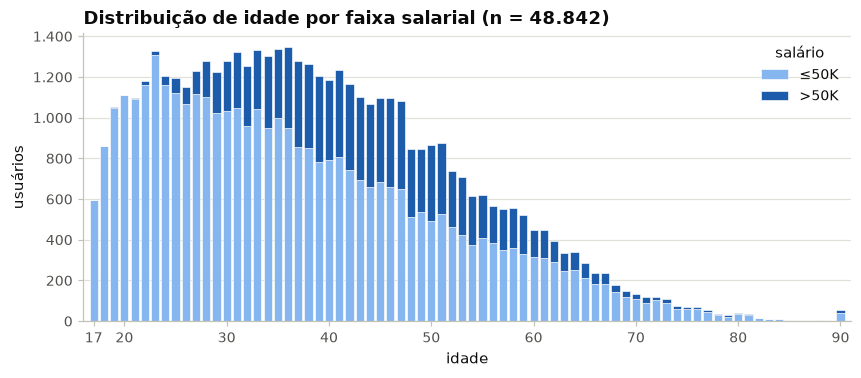

In [40]:
fig, ax = plt.subplots(figsize=(9, 3.4))
x = np.arange(IDADE_MIN, IDADE_MAX + 1)
ax.bar(x, contagem_idade_sal[:, LE50K], width=0.8, color="#86b6ef", edgecolor="white", linewidth=0.4, label="≤50K")
ax.bar(x, contagem_idade_sal[:, GT50K], width=0.8, bottom=contagem_idade_sal[:, LE50K], color="#1c5cab",
       edgecolor="white", linewidth=0.4, label=">50K")
ax.set_xlim(IDADE_MIN - 1, IDADE_MAX + 1)
ax.set_xticks([17, 20, 30, 40, 50, 60, 70, 80, 90])
ax.yaxis.set_major_formatter(EIXO_BR)
ax.set_xlabel("idade")
ax.set_ylabel("usuários")
ax.set_title(f"Distribuição de idade por faixa salarial (n = {fmt(N, 0)})")
ax.legend(title="salário", loc="upper right")
ax.grid(axis="x", visible=False)
salvar_figura(fig, "fig01_dados")
plt.show()

A proporção de salários >50K **muda muito dentro de uma mesma década**: é quase nula aos 20 anos e sobe rapidamente entre 25 e 45. Essa heterogeneidade dentro dos bins é o que gera viés no E2 quando uma consulta corta um bin (Seção 7).

## 2. Módulo GRR

Para um atributo com domínio de tamanho $k$, o usuário com valor verdadeiro $v$ reporta

$$\Pr[\mathrm{GRR}_{\varepsilon,k}(v)=y]=\begin{cases}p=\dfrac{e^\varepsilon}{e^\varepsilon+k-1}, & y=v,\\[6pt] q=\dfrac{1}{e^\varepsilon+k-1}, & y\neq v.\end{cases}$$

Como $p/q=e^\varepsilon$ para qualquer par de entradas e qualquer saída, o mecanismo satisfaz ε-LDP. O servidor conta $c_y$ (número de reports iguais a $y$) e estima $\hat n_y=(c_y-nq)/(p-q)$, que é **não viesado**, já que $\mathbb E[c_y]=n_y\,p+(n-n_y)\,q$. Para um conjunto $S$ de valores, $\hat q_S=\sum_{y\in S}\hat n_y=(c_S-n|S|q)/(p-q)$.

**Separação cliente/servidor.** As funções `grr_perturbar_*` rodam no dispositivo de cada usuário e são as únicas que tocam o valor verdadeiro. As funções `grr_contar` e `grr_estimar_frequencias` recebem **apenas** os reports.

In [41]:
# =====================================================================================
# MÓDULO GRR — implementação própria (sem bibliotecas de LDP)
# =====================================================================================

def grr_parametros(epsilon: float, k: int) -> tuple[float, float]:
    """Probabilidades do GRR_{ε,k}: p = e^ε/(e^ε+k−1) de reportar o valor verdadeiro e
    q = 1/(e^ε+k−1) de reportar cada um dos k−1 outros valores."""
    if k < 2:
        raise ValueError("o domínio precisa ter pelo menos 2 valores")
    e = math.exp(epsilon)
    return e / (e + k - 1), 1.0 / (e + k - 1)


# ------------------------------- LADO DO CLIENTE -------------------------------------
# Executado por cada usuário. São as ÚNICAS funções que veem o valor verdadeiro.

def grr_perturbar_usuario(valor: int, k: int, epsilon: float, rng: np.random.Generator) -> int:
    """Perturba o valor de UM usuário (valor ∈ {0, …, k−1}): com probabilidade p mantém o valor;
    caso contrário, sorteia uniformemente um dos k−1 outros valores."""
    p, _ = grr_parametros(epsilon, k)
    if rng.random() < p:
        return int(valor)
    outro = int(rng.integers(k - 1))              # uniforme em {0, …, k−2}
    return outro if outro < valor else outro + 1  # "pula" o valor verdadeiro → uniforme nos k−1 outros


def grr_perturbar_vetor(valores: np.ndarray, k: int, epsilon: float, rng: np.random.Generator) -> np.ndarray:
    """Mesma regra de `grr_perturbar_usuario`, aplicada a cada usuário de forma INDEPENDENTE
    (cada um com os seus próprios sorteios). É apenas a versão vetorizada, mais rápida."""
    valores = np.asarray(valores, dtype=np.int64)
    p, _ = grr_parametros(epsilon, k)
    manter = rng.random(valores.size) < p
    outros = rng.integers(0, k - 1, size=valores.size)
    outros = outros + (outros >= valores)         # pula o valor verdadeiro
    return np.where(manter, valores, outros)


# ------------------------------- LADO DO SERVIDOR ------------------------------------
# Recebe APENAS os reports perturbados.

def grr_contar(reports: np.ndarray, k: int) -> np.ndarray:
    """c_y = número de reports iguais a y, para y = 0, …, k−1."""
    return np.bincount(reports, minlength=k)


def grr_estimar_frequencias(reports: np.ndarray, k: int, epsilon: float) -> np.ndarray:
    """Estimador não viesado da contagem de cada valor: n̂_y = (c_y − n·q) / (p − q)."""
    p, q = grr_parametros(epsilon, k)
    n = len(reports)
    return (grr_contar(reports, k) - n * q) / (p - q)

In [42]:
# Probabilidade p de o usuário reportar o valor VERDADEIRO: para o mesmo ε, cai com o tamanho do domínio k
dominios = {"k = 2 (RR binário)": 2, "k = 16 (E2, w = 10)": 16, "k = 148 (E1)": 148}
tab_p = pd.DataFrame({nome: [grr_parametros(eps, k)[0] for eps in EPSILONS] for nome, k in dominios.items()},
                     index=pd.Index([fmt_eps(e) for e in EPSILONS], name="ε"))
tab_p_fmt = tab_p.apply(lambda coluna: coluna.map(lambda v: fmt(100 * v, 1) + "%"))
salvar_tabela("tab02_probabilidade_verdade", tab_p, tab_p_fmt)
display(tab_p_fmt)

,k = 2 (RR binário),"k = 16 (E2, w = 10)",k = 148 (E1)
ε,,,
"0,5","62,2%","9,9%","1,1%"
1,"73,1%","15,3%","1,8%"
2,"88,1%","33,0%","4,8%"
4,"98,2%","78,4%","27,1%"


Com ε = 1, apenas **1,8%** dos usuários do E1 reportam a célula verdadeira. Os outros 98,2% reportam uma célula aleatória, e o sinal precisa ser recuperado do meio desse ruído. Reduzir o domínio para k = 16 (E2) eleva esse número para 15,3%.

## 3. Módulo Consultas

Todas as consultas são **retângulos** no espaço Idade × Sal: um intervalo fechado de idades combinado com um subconjunto de salários. Nas marginais, o outro atributo cobre o domínio inteiro.

In [43]:
# =====================================================================================
# MÓDULO CONSULTAS
# =====================================================================================

@dataclass(frozen=True)
class Consulta:
    """Consulta de contagem retangular: conta os usuários com idade_min ≤ idade ≤ idade_max
    e salário em `salarios` (tupla de índices de SALARIOS)."""
    id: str
    predicado: str
    idade_min: int
    idade_max: int
    salarios: tuple[int, ...]
    tipo: str

    def contar(self, idades: np.ndarray, salarios: np.ndarray) -> int:
        """Resposta verdadeira q_j(D). Usa os dados originais, logo serve SÓ para avaliar o erro."""
        dentro = (idades >= self.idade_min) & (idades <= self.idade_max) & np.isin(salarios, self.salarios)
        return int(dentro.sum())


TODOS_SALARIOS = (LE50K, GT50K)
WORKLOAD = [
    Consulta("Q1",  "30 ≤ Idade ≤ 50 ∧ Sal = >50K", 30, 50, (GT50K,), "2D"),
    Consulta("Q2",  "Idade < 20 ∧ Sal = ≤50K",      IDADE_MIN, 19, (LE50K,), "2D"),
    Consulta("Q3",  "Idade ≥ 60 ∧ Sal = >50K",      60, IDADE_MAX, (GT50K,), "2D"),
    Consulta("Q4",  "20 ≤ Idade ≤ 30 ∧ Sal = >50K", 20, 30, (GT50K,), "2D"),
    Consulta("Q5",  "40 ≤ Idade ≤ 60 ∧ Sal = >50K", 40, 60, (GT50K,), "2D"),
    Consulta("Q6",  "Idade ≤ 30 ∧ Sal = ≤50K",      IDADE_MIN, 30, (LE50K,), "2D"),
    Consulta("Q7",  "Idade ≥ 40 ∧ Sal = ≤50K",      40, IDADE_MAX, (LE50K,), "2D"),
    Consulta("Q8",  "30 ≤ Idade ≤ 40 ∧ Sal = ≤50K", 30, 40, (LE50K,), "2D"),
    Consulta("Q9",  "Idade ≥ 50",                   50, IDADE_MAX, TODOS_SALARIOS, "Marginal (Idade)"),
    Consulta("Q10", "Sal = >50K",                   IDADE_MIN, IDADE_MAX, (GT50K,), "Marginal (Sal)"),
]
IDS_CONSULTAS = [c.id for c in WORKLOAD]


def respostas_verdadeiras(consultas: list[Consulta], idades: np.ndarray, salarios: np.ndarray) -> np.ndarray:
    """Vetor (q_1(D), …, q_m(D)) de respostas verdadeiras — usado apenas na avaliação."""
    return np.array([c.contar(idades, salarios) for c in consultas], dtype=float)


def nome_salarios(salarios: tuple[int, ...]) -> str:
    return "todos" if len(salarios) == K_SAL else ("≤50K" if salarios == (LE50K,) else ">50K")

In [44]:
Q_VERDADEIRO = respostas_verdadeiras(WORKLOAD, idades, salarios)
tab_workload = pd.DataFrame({
    "predicado": [c.predicado for c in WORKLOAD],
    "tipo": [c.tipo for c in WORKLOAD],
    "idades": [f"{c.idade_min}–{c.idade_max}" for c in WORKLOAD],
    "salário": [nome_salarios(c.salarios) for c in WORKLOAD],
    "resposta verdadeira": Q_VERDADEIRO.astype(int),
    "% de n": (100 * Q_VERDADEIRO / N).round(1),
}, index=pd.Index(IDS_CONSULTAS, name="consulta"))
tab_workload_fmt = tab_workload.assign(**{
    "resposta verdadeira": tab_workload["resposta verdadeira"].map(lambda v: fmt(v, 0)),
    "% de n": tab_workload["% de n"].map(lambda v: fmt(v, 1) + "%"),
})
salvar_tabela("tab03_workload", tab_workload, tab_workload_fmt)
display(tab_workload_fmt)

,predicado,tipo,idades,salário,resposta verdadeira,% de n
consulta,,,,,,
Q1,30 ≤ Idade ≤ 50 ∧ Sal = >50K,2D,30–50,>50K,7.820,"16,0%"
Q2,Idade < 20 ∧ Sal = ≤50K,2D,17–19,≤50K,2.507,"5,1%"
Q3,Idade ≥ 60 ∧ Sal = >50K,2D,60–90,>50K,985,"2,0%"
Q4,20 ≤ Idade ≤ 30 ∧ Sal = >50K,2D,20–30,>50K,990,"2,0%"
Q5,40 ≤ Idade ≤ 60 ∧ Sal = >50K,2D,40–60,>50K,6.629,"13,6%"
Q6,Idade ≤ 30 ∧ Sal = ≤50K,2D,17–30,≤50K,14.800,"30,3%"
Q7,Idade ≥ 40 ∧ Sal = ≤50K,2D,40–90,≤50K,13.918,"28,5%"
Q8,30 ≤ Idade ≤ 40 ∧ Sal = ≤50K,2D,30–40,≤50K,10.261,"21,0%"
Q9,Idade ≥ 50,Marginal (Idade),50–90,todos,10.674,"21,9%"


## 4. Módulo Estratégias

E1 e E2 são o **mesmo protocolo** com partições diferentes da idade:

* **E1**: cada idade é um bin próprio, e o domínio conjunto tem k = 74 · 2 = 148 células;
* **E2**: a idade $i$ é mapeada para o bin $B(i)$ e o usuário aplica o GRR ao par $(B(i), s)$, com k = k<sub>B</sub> · 2.

A partição é **pública**: clientes e servidor a conhecem. No servidor, a resposta de uma consulta é $\hat q_j=\sum_c W_{j,c}\,\hat n_c$, onde $W_{j,c}$ é a fração das idades do bin da célula $c$ que caem dentro do retângulo da consulta $j$. Quando os limites coincidem, $W$ vale 0 ou 1 e a resposta é a soma das células, exatamente como no E1. Quando a borda da consulta **atravessa** um bin, somamos só a fração coberta, supondo idades uniformes dentro do bin, porque o servidor não enxerga nada mais fino que o bin. Essa hipótese é a origem do **viés** do E2.

**Pós-processamento (truncamento).** Opcionalmente, cada resposta é projetada em $[0, n]$. Isso não consome privacidade e nunca aumenta o erro de uma consulta, porque a resposta verdadeira também está em $[0, n]$. Reportamos todos os resultados com e sem truncamento.

In [45]:
# =====================================================================================
# MÓDULO ESTRATÉGIAS
# =====================================================================================

Bins = tuple[tuple[int, int], ...]        # ((início, fim), …): intervalos de idade fechados, em ordem


@dataclass(frozen=True)
class Estrategia:
    """Descrição PÚBLICA do protocolo, conhecida por clientes e servidor: uma partição das idades
    17–90 em bins. O GRR atua no domínio conjunto (bin de idade) × (salário), com k = k_B · k_Sal."""
    nome: str
    bins: Bins

    @property
    def k_bins(self) -> int:
        return len(self.bins)

    @property
    def k(self) -> int:
        return self.k_bins * K_SAL

    def bin_da_idade(self) -> np.ndarray:
        """Tabela B(i): idade → índice do bin que a contém."""
        tabela = np.full(IDADE_MAX + 1, -1, dtype=np.int64)
        for b, (ini, fim) in enumerate(self.bins):
            tabela[ini:fim + 1] = b
        return tabela


def criar_bins_uniformes(largura: int, origem: int = 0) -> Bins:
    """Bins de largura `largura`, começando nas idades a tais que (a − origem) é múltiplo da largura.
      • origem = 0  → grade em múltiplos de w; para w = 10: [17–19], [20–29], …, [70–79], [80–90];
      • origem = 17 → grade iniciando no menor valor do domínio; para w = 10: [17–26], [27–36], …, [87–90].
    O primeiro bin começa em 17 (início do domínio). O último é ajustado para incluir a maior idade (90):
    se 90 ficaria isolada num bin próprio, ela é incorporada ao bin anterior."""
    inicios = [IDADE_MIN] + [a for a in range(IDADE_MIN + 1, IDADE_MAX + 1) if (a - origem) % largura == 0]
    if largura > 1 and inicios[-1] == IDADE_MAX:
        inicios.pop()
    fins = [proximo - 1 for proximo in inicios[1:]] + [IDADE_MAX]
    return tuple(zip(inicios, fins))


def criar_bins_por_cortes(cortes: list[int]) -> Bins:
    """Partição arbitrária (não uniforme): `cortes` são as idades em que começa um novo bin."""
    inicios = sorted({IDADE_MIN, *cortes})
    fins = [proximo - 1 for proximo in inicios[1:]] + [IDADE_MAX]
    return tuple(zip(inicios, fins))


def estrategia_E1() -> Estrategia:
    """E1 — GRR direto no domínio conjunto Idade × Sal: cada idade é o seu próprio bin."""
    return Estrategia("E1", tuple((i, i) for i in range(IDADE_MIN, IDADE_MAX + 1)))


def estrategia_E2(largura: int, origem: int = 0) -> Estrategia:
    """E2 — GRR sobre (bin de idade, salário), com bins de largura fixa."""
    sufixo = "" if origem == 0 else f", início {origem}"
    return Estrategia(f"E2 (w={largura}{sufixo})", criar_bins_uniformes(largura, origem))


# ------------------------------- LADO DO CLIENTE -------------------------------------

def cliente_codificar(estrategia: Estrategia, idade, salario):
    """Mapeia o par (i, s) do usuário para o índice da célula no domínio conjunto: B(i) · k_Sal + s."""
    return estrategia.bin_da_idade()[idade] * K_SAL + salario


def cliente_gerar_reports(estrategia: Estrategia, idades: np.ndarray, salarios: np.ndarray,
                          epsilon: float, rng: np.random.Generator) -> np.ndarray:
    """Cada usuário codifica (B(i), s) e aplica GRR_{ε,k} localmente. Só os reports saem dos clientes."""
    valores = cliente_codificar(estrategia, np.asarray(idades), np.asarray(salarios))
    return grr_perturbar_vetor(valores, estrategia.k, epsilon, rng)


# ------------------------------- LADO DO SERVIDOR ------------------------------------

def servidor_estimar_celulas(estrategia: Estrategia, reports: np.ndarray, epsilon: float) -> np.ndarray:
    """n̂ de cada célula (bin, salário), como matriz k_B × k_Sal."""
    return grr_estimar_frequencias(reports, estrategia.k, epsilon).reshape(estrategia.k_bins, K_SAL)


def servidor_pesos_consultas(estrategia: Estrategia, consultas: list[Consulta]) -> np.ndarray:
    """Matriz W (m × k): W[j, (b, s)] = fração das idades do bin b que estão no intervalo da consulta j,
    para s entre os salários da consulta. Vale 1 se o bin está inteiro dentro da consulta e fica
    entre 0 e 1 quando a borda da consulta ATRAVESSA o bin (hipótese de idades uniformes no bin)."""
    W = np.zeros((len(consultas), estrategia.k_bins, K_SAL))
    for j, c in enumerate(consultas):
        for b, (ini, fim) in enumerate(estrategia.bins):
            sobreposicao = min(fim, c.idade_max) - max(ini, c.idade_min) + 1
            if sobreposicao > 0:
                W[j, b, list(c.salarios)] = sobreposicao / (fim - ini + 1)
    return W.reshape(len(consultas), estrategia.k)


def truncar_respostas(q_hat: np.ndarray, n: int) -> np.ndarray:
    """Pós-processamento: projeta cada resposta em [0, n]."""
    return np.clip(q_hat, 0, n)


def servidor_responder(estrategia: Estrategia, reports: np.ndarray, epsilon: float,
                       consultas: list[Consulta], truncar: bool = False) -> np.ndarray:
    """Respostas estimadas q̂_j = Σ_c W[j, c] · n̂_c, a partir APENAS dos reports."""
    n_hat = servidor_estimar_celulas(estrategia, reports, epsilon).ravel()
    q_hat = servidor_pesos_consultas(estrategia, consultas) @ n_hat
    return truncar_respostas(q_hat, len(reports)) if truncar else q_hat

## 5. Módulo Avaliação

* **Métrica (Seção 3.3):** em cada execução, $\mathrm{MAE}=\frac{1}{10}\sum_{j=1}^{10}|q_j(D)-\hat q_j|$. Reportamos a média e o desvio-padrão amostral (ddof = 1) do MAE nas R = 10 repetições, além do MAE de cada consulta (média de $|q_j(D)-\hat q_j|$ nas repetições).
* **Erro teórico (ferramenta de análise).** Como o estimador é linear nas contagens, dá para calcular exatamente o **viés** e a **variância** de cada resposta. Com n ≈ 49 mil, o TCL torna a resposta praticamente normal, então o erro absoluto esperado é a média de uma normal dobrada $|\mathcal N(\text{viés}, \sigma^2)|$. Essa conta usa os dados verdadeiros e por isso **não** faz parte do mecanismo. Serve para validar a implementação (Seção 9.7) e para explicar os resultados (Seções 9.5 e 9.8).

$$\operatorname{Var}[\hat q_j]=\frac{1}{(p-q)^2}\sum_{v} n_v\Big[q\,\lVert w\rVert^2+(p-q)\,w_v^2-\big(q\textstyle\sum_c w_c+(p-q)\,w_v\big)^2\Big],\qquad w=W_{j,\cdot}$$

In [46]:
# =====================================================================================
# MÓDULO AVALIAÇÃO — junto com os clientes, é a única parte que usa os dados originais
# =====================================================================================

def executar_protocolo(estrategias: list[Estrategia], epsilons: list[float], sementes: list[int],
                       consultas: list[Consulta], idades: np.ndarray, salarios: np.ndarray) -> pd.DataFrame:
    """Para cada estratégia × ε × repetição:
         dados → [CLIENTES] reports → [SERVIDOR] q̂ (sem e com truncamento) → [AVALIAÇÃO] |q − q̂|.
    Devolve uma tabela 'longa', com uma linha por (estratégia, ε, repetição, consulta)."""
    q_true = respostas_verdadeiras(consultas, idades, salarios)
    blocos = []
    for estrategia in estrategias:
        for eps in epsilons:
            for repeticao, semente in enumerate(sementes):
                rng = np.random.default_rng(semente)
                reports = cliente_gerar_reports(estrategia, idades, salarios, eps, rng)   # lado do cliente
                q_hat = servidor_responder(estrategia, reports, eps, consultas)            # lado do servidor
                q_hat_trunc = truncar_respostas(q_hat, len(reports))                       # pós-processamento
                blocos.append(pd.DataFrame({
                    "estrategia": estrategia.nome, "k": estrategia.k, "epsilon": eps,
                    "repeticao": repeticao, "semente": semente, "consulta": [c.id for c in consultas],
                    "verdadeiro": q_true, "estimado": q_hat, "estimado_trunc": q_hat_trunc,
                    "erro_abs": np.abs(q_true - q_hat), "erro_abs_trunc": np.abs(q_true - q_hat_trunc),
                }))
    return pd.concat(blocos, ignore_index=True)


def resumo_mae(resultados: pd.DataFrame) -> pd.DataFrame:
    """MAE de cada execução (média de |q_j − q̂_j| nas 10 consultas) → média e desvio-padrão
    amostral nas R repetições, sem truncamento ('mae', 'dp') e com truncamento ('mae_trunc', 'dp_trunc')."""
    por_execucao = (resultados.groupby(["estrategia", "epsilon", "repeticao"], sort=False)
                    [["erro_abs", "erro_abs_trunc"]].mean())
    resumo = por_execucao.groupby(["estrategia", "epsilon"], sort=False).agg(["mean", "std"])
    resumo.columns = ["mae", "dp", "mae_trunc", "dp_trunc"]
    return resumo.sort_index()


def mae_por_consulta(resultados: pd.DataFrame) -> pd.DataFrame:
    """MAE de cada consulta (média de |q_j − q̂_j| nas R repetições)."""
    return (resultados.groupby(["estrategia", "epsilon", "consulta"], sort=False)
            .agg(verdadeiro=("verdadeiro", "first"), mae=("erro_abs", "mean"), dp=("erro_abs", "std"),
                 mae_trunc=("erro_abs_trunc", "mean"))
            .sort_index())


def _cdf_normal(x: float) -> float:
    return 0.5 * (1.0 + math.erf(x / math.sqrt(2.0)))


def erro_teorico(estrategia: Estrategia, epsilon: float, consultas: list[Consulta],
                 idades: np.ndarray, salarios: np.ndarray) -> pd.DataFrame:
    """Viés, desvio-padrão do ruído e erro absoluto esperado de cada consulta (ANÁLISE; usa os dados reais).
      viés_j    = E[q̂_j] − q_j = Σ_c W[j, c]·n_c − q_j   (≠ 0 só quando a consulta atravessa um bin)
      Var[q̂_j]  = Σ_v n_v [q‖w‖² + (p−q)w_v² − (qΣw + (p−q)w_v)²] / (p−q)²
      E|q̂_j − q_j| = média da normal dobrada |N(viés_j, Var[q̂_j])|"""
    p, q = grr_parametros(epsilon, estrategia.k)
    d = p - q
    W = servidor_pesos_consultas(estrategia, consultas)
    n_celula = np.bincount(cliente_codificar(estrategia, idades, salarios), minlength=estrategia.k)
    q_true = respostas_verdadeiras(consultas, idades, salarios)
    vies = W @ n_celula - q_true
    soma_w = W.sum(axis=1, keepdims=True)
    soma_w2 = (W ** 2).sum(axis=1, keepdims=True)
    var_um_usuario = q * soma_w2 + d * W ** 2 - (q * soma_w + d * W) ** 2   # [j, v]: usuário cuja célula é v
    dp = np.sqrt(var_um_usuario @ n_celula) / d
    esperado = [s * math.sqrt(2 / math.pi) * math.exp(-b * b / (2 * s * s)) + b * (1 - 2 * _cdf_normal(-b / s))
                for b, s in zip(vies, dp)]
    return pd.DataFrame({"consulta": [c.id for c in consultas], "verdadeiro": q_true, "vies": vies,
                         "dp_ruido": dp, "ruido_esperado": dp * math.sqrt(2 / math.pi),
                         "erro_esperado": esperado})


def mae_teorico(estrategia: Estrategia, epsilon: float) -> float:
    """MAE esperado = média do erro absoluto esperado das 10 consultas."""
    return float(erro_teorico(estrategia, epsilon, WORKLOAD, idades, salarios)["erro_esperado"].mean())

## 6. Testes de corretude

Verificações automáticas da implementação. Se alguma falhar, a célula para com erro.

In [47]:
def verificar(condicao: bool, descricao: str) -> None:
    assert condicao, "FALHOU: " + descricao
    print("✓", descricao)


# T1 — parâmetros: razão p/q = e^ε (garantia ε-LDP) e distribuição de probabilidade válida
verificar(all(math.isclose(grr_parametros(e, k)[0] / grr_parametros(e, k)[1], math.exp(e)) and
              math.isclose(grr_parametros(e, k)[0] + (k - 1) * grr_parametros(e, k)[1], 1.0)
              for e in (0.5, 1, 2, 4, 8) for k in (2, 16, 148)),
          "T1: p/q = e^ε (ε-LDP) e p + (k−1)·q = 1 para todos os ε e k testados")

# T2 — o cliente reporta v com prob. p e cada outro valor com prob. q (versão de 1 usuário e vetorizada)
rng_teste = np.random.default_rng(0)
k_t, eps_t, v_t = 6, 1.0, 2
p_t, q_t = grr_parametros(eps_t, k_t)
esperado_t = np.full(k_t, q_t)
esperado_t[v_t] = p_t
for nome, saidas in [("vetorizada", grr_perturbar_vetor(np.full(200_000, v_t), k_t, eps_t, rng_teste)),
                     ("1 usuário", np.array([grr_perturbar_usuario(v_t, k_t, eps_t, rng_teste) for _ in range(50_000)]))]:
    frequencia = np.bincount(saidas, minlength=k_t) / len(saidas)
    tolerancia = 5 * np.sqrt(esperado_t * (1 - esperado_t) / len(saidas))
    verificar(bool(np.all(np.abs(frequencia - esperado_t) < tolerancia)),
              f"T2: cliente ({nome}) reporta o valor verdadeiro com prob. p e cada outro com prob. q")

# T3 — o estimador do servidor é não viesado: média de 300 execuções ≈ contagem verdadeira de cada célula
E_t = estrategia_E2(10)
celulas_verdadeiras = np.bincount(cliente_codificar(E_t, idades, salarios), minlength=E_t.k)
estimativas = np.array([
    servidor_estimar_celulas(E_t, cliente_gerar_reports(E_t, idades, salarios, 1.0, np.random.default_rng(s)), 1.0).ravel()
    for s in range(300)])
z = np.abs(estimativas.mean(axis=0) - celulas_verdadeiras) / (estimativas.std(axis=0, ddof=1) / np.sqrt(len(estimativas)))
verificar(bool(np.all(z < 4)), f"T3: n̂ não viesado nas {E_t.k} células de E2 (w=10), ε=1, 300 execuções (máx |z| = {z.max():.2f})")

# T4 — em E1, somar as células do retângulo reproduz exatamente as respostas verdadeiras
E1_t = estrategia_E1()
celulas_E1 = np.bincount(cliente_codificar(E1_t, idades, salarios), minlength=E1_t.k)
verificar(np.allclose(servidor_pesos_consultas(E1_t, WORKLOAD) @ celulas_E1, Q_VERDADEIRO),
          "T4: E1 aplicado às contagens verdadeiras reproduz exatamente as 10 respostas verdadeiras")

# T5 — a soma das células coincide com a fórmula do enunciado q̂ = (c_S − n|S|q)/(p − q)
reports_t = cliente_gerar_reports(E1_t, idades, salarios, 1.0, np.random.default_rng(1))
p1, q1 = grr_parametros(1.0, E1_t.k)
c_t = grr_contar(reports_t, E1_t.k)
formula = [(c_t[w > 0].sum() - len(reports_t) * (w > 0).sum() * q1) / (p1 - q1)
           for w in servidor_pesos_consultas(E1_t, WORKLOAD)]
verificar(np.allclose(formula, servidor_responder(E1_t, reports_t, 1.0, WORKLOAD)),
          "T5: soma de n̂ nas células = fórmula (c_S − n|S|q)/(p − q) da Seção 2.2")

# T6 — as partições geradas cobrem 17–90 sem buracos nem sobreposições; E1 = E2 com w = 1
def particao_valida(bins: Bins) -> bool:
    return (bins[0][0] == IDADE_MIN and bins[-1][1] == IDADE_MAX and all(i <= f for i, f in bins)
            and all(b[0] == a[1] + 1 for a, b in zip(bins, bins[1:])))
verificar(all(particao_valida(criar_bins_uniformes(w, o)) for w in range(1, 75) for o in (0, IDADE_MIN)),
          "T6: toda partição uniforme (w = 1…74, grade em 0 ou em 17) cobre 17–90 sem buracos/sobreposição")
verificar(criar_bins_uniformes(1) == E1_t.bins, "T7: E1 é o caso particular de E2 com bins de largura 1")

✓ T1: p/q = e^ε (ε-LDP) e p + (k−1)·q = 1 para todos os ε e k testados
✓ T2: cliente (vetorizada) reporta o valor verdadeiro com prob. p e cada outro com prob. q
✓ T2: cliente (1 usuário) reporta o valor verdadeiro com prob. p e cada outro com prob. q
✓ T3: n̂ não viesado nas 16 células de E2 (w=10), ε=1, 300 execuções (máx |z| = 2.68)
✓ T4: E1 aplicado às contagens verdadeiras reproduz exatamente as 10 respostas verdadeiras
✓ T5: soma de n̂ nas células = fórmula (c_S − n|S|q)/(p − q) da Seção 2.2
✓ T6: toda partição uniforme (w = 1…74, grade em 0 ou em 17) cobre 17–90 sem buracos/sobreposição
✓ T7: E1 é o caso particular de E2 com bins de largura 1


## 7. Escolha do tamanho do bin (E2)

O enunciado pede que a largura seja escolhida **a partir do workload**, olhando quais faixas etárias são consultadas e se os limites das consultas coincidem com os limites dos bins. Isso também é o correto do ponto de vista de privacidade: o workload é público, e escolher a partição olhando os dados consumiria orçamento. A escolha é feita aqui, **antes** dos experimentos, e só depois confirmada por eles (Seção 9).

**Passo 1 — Onde as consultas cortam o eixo da idade?** Uma consulta que começa em *a* exige que algum bin comece em *a*. Uma consulta que termina em *b* (inclusive) exige que algum bin comece em *b* + 1.

In [48]:
cortes_workload = sorted({c.idade_min for c in WORKLOAD if c.idade_min > IDADE_MIN} |
                         {c.idade_max + 1 for c in WORKLOAD if c.idade_max < IDADE_MAX})
print("Idades em que um bin precisa começar para responder TODAS as consultas exatamente:", cortes_workload)

Idades em que um bin precisa começar para responder TODAS as consultas exatamente: [20, 30, 31, 40, 41, 50, 51, 60, 61]


Todos os limites estão nas **dezenas** (20, 30, 40, 50, 60). Os limites superiores são inclusivos (≤ 30, ≤ 40, ≤ 50, ≤ 60), então também exigem cortes em 31, 41, 51 e 61. Nenhuma largura uniforme maior que 1 contém os dois cortes vizinhos (30 e 31, por exemplo). Logo, **com bins uniformes, alguma consulta sempre atravessará um bin**. A questão é minimizar o estrago.

**Passo 2 — Alinhamento.** Uma grade de largura 10 ancorada nas dezenas, ([17–19], [20–29], …, [70–79], [80–90]), coincide com todos os limites inferiores. Cada limite superior inclusivo invade o bin seguinte em **uma única idade**, ou seja, 1/10 do bin. Já a leitura literal "bins de 10 a partir de 17" ([17–26], [27–36], …) desalinha quase todas as consultas.

**Passo 3 — Compromisso resolução × ruído.** Bins menores preservam detalhe, mas aumentam k e o número de células somadas por consulta, e o ruído do GRR cresce com ambos. Bins maiores reduzem o ruído, mas aumentam o viés das consultas que os atravessam. Candidatas avaliadas:

* **largura** w ∈ {2, 5, 10, 15, 20}, com grade em múltiplos de w. Para w ∈ {2, 5, 10}, essa grade coincide com as dezenas;
* **alinhamento**: grade iniciando em 17 (leitura literal), para w ∈ {5, 10, 20};
* **extra, fora do protocolo**: E2\*, uma partição *não uniforme* com cortes exatamente nos limites do workload. É a partição mais grossa que responde tudo sem viés.

In [49]:
LARGURAS = [2, 5, 10, 15, 20]
E1 = estrategia_E1()
E2_LARGURAS = [estrategia_E2(w) for w in LARGURAS]                              # grade em múltiplos de w
E2_INICIO_17 = [estrategia_E2(w, origem=IDADE_MIN) for w in (5, 10, 20)]        # grade a partir de 17
E2_WORKLOAD = Estrategia("E2* (bins do workload)", criar_bins_por_cortes(cortes_workload))  # extra
ESTRATEGIAS = [E1, *E2_LARGURAS, *E2_INICIO_17, E2_WORKLOAD]

E2 = estrategia_E2(10)              # ESCOLHA PRINCIPAL: w = 10, grade alinhada às dezenas
NOME_E2 = E2.nome                   # "E2 (w=10)"


def analisar_alinhamento(estrategia: Estrategia, consultas: list[Consulta]) -> pd.DataFrame:
    """Para cada consulta: nº de células somadas e bins atravessados pela borda (com a fração coberta)."""
    W = servidor_pesos_consultas(estrategia, consultas)
    linhas = []
    for c, w in zip(consultas, W):
        atravessados = []
        for ini, fim in estrategia.bins:
            sobreposicao = min(fim, c.idade_max) - max(ini, c.idade_min) + 1
            if 0 < sobreposicao < fim - ini + 1:
                atravessados.append(f"{ini}–{fim} ({sobreposicao}/{fim - ini + 1})")
        linhas.append({"consulta": c.id, "células somadas": int((w > 0).sum()),
                       "bins atravessados": "; ".join(atravessados) or "—", "exata": not atravessados})
    return pd.DataFrame(linhas).set_index("consulta")


def descrever_bins(estrategia: Estrategia) -> str:
    if estrategia.k_bins > 15:
        return f"{estrategia.k_bins} bins"
    return ", ".join(f"{i}–{f}" if i != f else str(i) for i, f in estrategia.bins)


tab_candidatas = pd.DataFrame([{
    "estratégia": e.nome, "bins de idade": descrever_bins(e), "k_B": e.k_bins, "k": e.k,
    "consultas exatas": int(analisar_alinhamento(e, WORKLOAD)["exata"].sum()),
    "p (ε = 1)": grr_parametros(1.0, e.k)[0],
} for e in ESTRATEGIAS]).set_index("estratégia")
salvar_tabela("tab04_candidatas", tab_candidatas,
              tab_candidatas.assign(**{"p (ε = 1)": tab_candidatas["p (ε = 1)"].map(lambda v: fmt(100 * v, 1) + "%")}))
display(tab_candidatas.assign(**{"p (ε = 1)": tab_candidatas["p (ε = 1)"].map(lambda v: fmt(100 * v, 1) + "%")}))

,bins de idade,k_B,k,consultas exatas,p (ε = 1)
estratégia,,,,,
E1,74 bins,74,148,10,"1,8%"
E2 (w=2),37 bins,37,74,5,"3,6%"
E2 (w=5),"17–19, 20–24, 25–29, 30–34, 35–39, 40–44, 45–4...",15,30,5,"8,6%"
E2 (w=10),"17–19, 20–29, 30–39, 40–49, 50–59, 60–69, 70–7...",8,16,5,"15,3%"
E2 (w=15),"17–29, 30–44, 45–59, 60–74, 75–90",5,10,2,"23,2%"
E2 (w=20),"17–19, 20–39, 40–59, 60–79, 80–90",5,10,4,"23,2%"
"E2 (w=5, início 17)","17–21, 22–26, 27–31, 32–36, 37–41, 42–46, 47–5...",15,30,1,"8,6%"
"E2 (w=10, início 17)","17–26, 27–36, 37–46, 47–56, 57–66, 67–76, 77–8...",8,16,1,"15,3%"
"E2 (w=20, início 17)","17–36, 37–56, 57–76, 77–90",4,8,1,"28,0%"


In [50]:
# Como cada consulta é respondida: E1 × E2 (w=10, alinhado) × E2 (w=10, início 17)
E2_10_17 = next(e for e in E2_INICIO_17 if e.nome == "E2 (w=10, início 17)")
alinh_E2 = analisar_alinhamento(E2, WORKLOAD)
alinh_17 = analisar_alinhamento(E2_10_17, WORKLOAD)
tab_alinhamento = pd.DataFrame({
    "predicado": [c.predicado for c in WORKLOAD],
    "células E1": analisar_alinhamento(E1, WORKLOAD)["células somadas"].to_numpy(),
    "células E2 (w=10)": alinh_E2["células somadas"].to_numpy(),
    "bin atravessado E2 (w=10)": alinh_E2["bins atravessados"].to_numpy(),
    "bins atravessados E2 (w=10, início 17)": alinh_17["bins atravessados"].to_numpy(),
}, index=pd.Index(IDS_CONSULTAS, name="consulta"))
salvar_tabela("tab05_alinhamento_w10", tab_alinhamento)
display(tab_alinhamento)

,predicado,células E1,células E2 (w=10),bin atravessado E2 (w=10),"bins atravessados E2 (w=10, início 17)"
consulta,,,,,
Q1,30 ≤ Idade ≤ 50 ∧ Sal = >50K,21,3,50–59 (1/10),27–36 (7/10); 47–56 (4/10)
Q2,Idade < 20 ∧ Sal = ≤50K,3,1,—,17–26 (3/10)
Q3,Idade ≥ 60 ∧ Sal = >50K,31,3,—,57–66 (7/10)
Q4,20 ≤ Idade ≤ 30 ∧ Sal = >50K,11,2,30–39 (1/10),17–26 (7/10); 27–36 (4/10)
Q5,40 ≤ Idade ≤ 60 ∧ Sal = >50K,21,3,60–69 (1/10),37–46 (7/10); 57–66 (4/10)
Q6,Idade ≤ 30 ∧ Sal = ≤50K,14,3,30–39 (1/10),27–36 (4/10)
Q7,Idade ≥ 40 ∧ Sal = ≤50K,51,5,—,37–46 (7/10)
Q8,30 ≤ Idade ≤ 40 ∧ Sal = ≤50K,11,2,40–49 (1/10),27–36 (7/10); 37–46 (4/10)
Q9,Idade ≥ 50,82,8,—,47–56 (7/10)


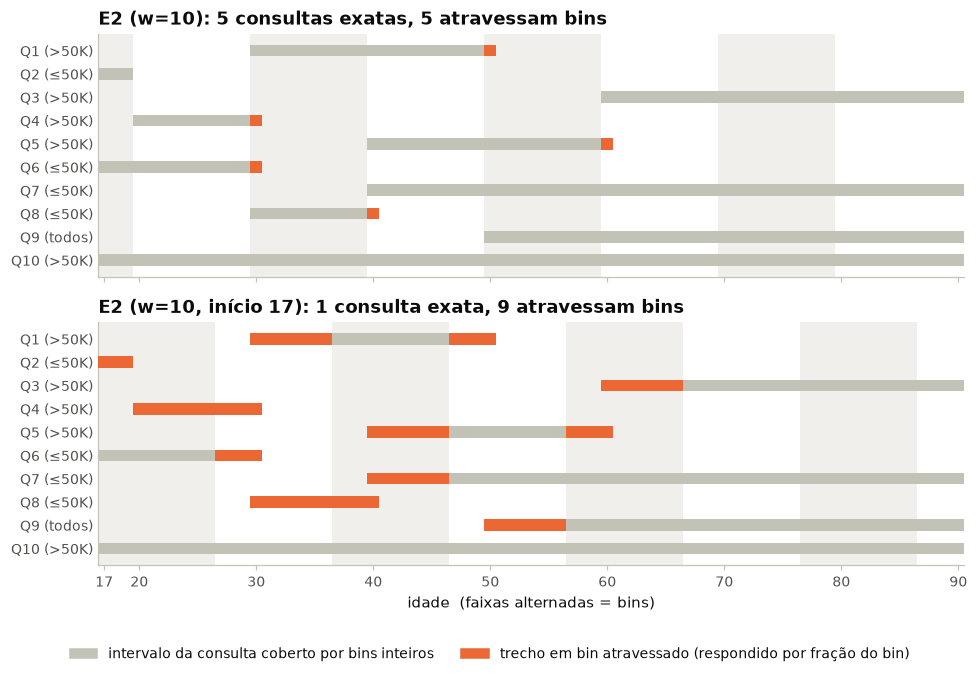

In [51]:
def figura_mapa_workload(estrategias: list[Estrategia], consultas: list[Consulta]):
    """Intervalo de idade de cada consulta sobre a grade de bins. Em laranja, os trechos que caem em
    bins atravessados pela borda da consulta (respondidos por fração do bin → fonte de viés)."""
    fig, eixos = plt.subplots(len(estrategias), 1, figsize=(9, 3.0 * len(estrategias)), sharex=True)
    for ax, est in zip(np.atleast_1d(eixos), estrategias):
        for b, (ini, fim) in enumerate(est.bins):                      # bins em faixas alternadas
            if b % 2 == 0:
                ax.axvspan(ini - 0.5, fim + 0.5, color=COR_FAIXA, lw=0, zorder=0)
        n_atravessam = 0
        for j, c in enumerate(consultas):
            y = len(consultas) - 1 - j
            ax.barh(y, c.idade_max - c.idade_min + 1, left=c.idade_min - 0.5, height=0.5, color=COR_NEUTRA_CLARA, zorder=2)
            atravessa = False
            for ini, fim in est.bins:
                lo, hi = max(ini, c.idade_min), min(fim, c.idade_max)
                if lo <= hi and hi - lo + 1 < fim - ini + 1:
                    ax.barh(y, hi - lo + 1, left=lo - 0.5, height=0.5, color=COR_E2, zorder=3)
                    atravessa = True
            n_atravessam += atravessa
        ax.set_yticks(range(len(consultas)), [f"{c.id} ({nome_salarios(c.salarios)})" for c in reversed(consultas)])
        ax.set_title(f"{est.nome}: {plural(len(consultas) - n_atravessam, 'consulta exata', 'consultas exatas')}, "
                     f"{plural(n_atravessam, 'atravessa bins', 'atravessam bins')}")
        ax.grid(False)
        ax.tick_params(axis="y", length=0)
    ax.set_xlim(IDADE_MIN - 0.5, IDADE_MAX + 0.5)
    ax.set_xticks([17, 20, 30, 40, 50, 60, 70, 80, 90])
    ax.set_xlabel("idade  (faixas alternadas = bins)")
    fig.legend(handles=[Patch(color=COR_NEUTRA_CLARA, label="intervalo da consulta coberto por bins inteiros"),
                        Patch(color=COR_E2, label="trecho em bin atravessado (respondido por fração do bin)")],
               loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.03))
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig


fig = figura_mapa_workload([E2, E2_10_17], WORKLOAD)
salvar_figura(fig, "fig02_mapa_workload_bins")
plt.show()

**Escolha principal: E2 com w = 10, alinhado às dezenas** (8 bins, k = 16). O motivo vem do workload, sem olhar os dados:

1. a resolução que o workload pede é a **década**: todos os limites são 20, 30, 40, 50 ou 60;
2. com a grade alinhada, **5 consultas são exatas** (Q2, Q3, Q7, Q9, Q10) e as outras 5 atravessam **um único bin, em uma única idade** (1/10 do bin). É o menor desalinhamento possível com bins uniformes de largura > 1;
3. o domínio cai de 148 para 16 células: p vai de 1,8% para 15,3% (ε = 1), e cada consulta passa a somar no máximo 8 células, contra até 82 no E1.

A Seção 9.3 confirma a escolha nos experimentos e mostra que o compromisso muda com ε.

## 8. Experimentos

**Configuração experimental (resumo):**

| Item | Valor |
|---|---|
| Dataset | `dados_censo.csv`, n = 48.842 usuários; Idade ∈ {17, …, 90} (74 valores); Salário ∈ {≤50K, >50K} |
| Workload | Q1–Q10 (Seção 3): 8 consultas 2D, 1 marginal de Idade, 1 marginal de Salário |
| Estratégias | **E1**: GRR no domínio conjunto (k = 148). **E2**: GRR em (bin de idade, salário), w = 10 alinhado às dezenas (k = 16). Para a análise de bins: w ∈ {2, 5, 15, 20}, grade iniciando em 17 (w ∈ {5, 10, 20}) e o extra E2\* (bins do workload, k = 20) |
| Orçamentos | ε ∈ {0,5; 1; 2; 4}, orçamento total por usuário (cada usuário envia um único report) |
| Repetições e sementes | R = 10 por configuração; repetição r usa `np.random.default_rng(2026 + r)`, as mesmas para todas as configurações |
| Consultas que atravessam bins | fração do bin proporcional às idades cobertas (hipótese de uniformidade) |
| Pós-processamento | truncamento de cada resposta em [0, n]; resultados reportados **com e sem** truncamento |
| Métrica | MAE de cada execução (média das 10 consultas): média ± desvio-padrão amostral nas R repetições; MAE por consulta |

**Protocolo principal:** 10 estratégias (E1, E2 com cinco larguras, três variantes de alinhamento e o extra E2\*) × 4 valores de ε × 10 repetições = 400 execuções. Cada execução gera reports novos para todos os usuários.

**Experimento complementar:** E1, E2 (w = 10) e E2\* com ε ∈ {0,5; 1; …; 8}, para investigar se a melhor estratégia muda para ε além da faixa do protocolo.

In [52]:
inicio = time.perf_counter()
resultados = executar_protocolo(ESTRATEGIAS, EPSILONS, SEMENTES, WORKLOAD, idades, salarios)
print(f"{len(ESTRATEGIAS)} estratégias × {len(EPSILONS)} ε × {N_REPETICOES} repetições = "
      f"{len(ESTRATEGIAS) * len(EPSILONS) * N_REPETICOES} execuções em {time.perf_counter() - inicio:.1f} s")
resultados.to_csv(DIR_RESULTADOS / "resultados_brutos.csv", index=False)

# Erro teórico (análise) para todas as configurações do protocolo
teoria = pd.concat([erro_teorico(e, eps, WORKLOAD, idades, salarios).assign(estrategia=e.nome, epsilon=eps)
                    for e in ESTRATEGIAS for eps in EPSILONS], ignore_index=True)

resumo = resumo_mae(resultados).join(
    teoria.groupby(["estrategia", "epsilon"])["erro_esperado"].mean().rename("mae_teorico"))
pq = mae_por_consulta(resultados)
CONFIGS_LARGURA = ["E1"] + [e.nome for e in E2_LARGURAS]                       # E1 = largura 1
CONFIGS_TABELA = CONFIGS_LARGURA + [e.nome for e in E2_INICIO_17] + [E2_WORKLOAD.nome]
resumo.to_csv(DIR_TABELAS / "resumo_mae_todas_estrategias.csv")
pq.to_csv(DIR_TABELAS / "mae_por_consulta_todas_estrategias.csv")
resultados.head(12)

10 estratégias × 4 ε × 10 repetições = 400 execuções em 1.6 s


,estrategia,k,epsilon,repeticao,semente,consulta,verdadeiro,estimado,estimado_trunc,erro_abs,erro_abs_trunc
0,E1,148,0.5,0,2026,Q1,7820.0,17405.748962,17405.748962,9585.748962,9585.748962
1,E1,148,0.5,0,2026,Q2,2507.0,1897.315532,1897.315532,609.684468,609.684468
2,E1,148,0.5,0,2026,Q3,985.0,3489.334765,3489.334765,2504.334765,2504.334765
3,E1,148,0.5,0,2026,Q4,990.0,-1674.158727,0.000000,2664.158727,990.000000
4,E1,148,0.5,0,2026,Q5,6629.0,-4820.940086,0.000000,11449.940086,6629.000000
5,E1,148,0.5,0,2026,Q6,14800.0,15575.612128,15575.612128,775.612128,775.612128
6,E1,148,0.5,0,2026,Q7,13918.0,9798.533877,9798.533877,4119.466123,4119.466123
7,E1,148,0.5,0,2026,Q8,10261.0,30405.598663,30405.598663,20144.598663,20144.598663
8,E1,148,0.5,0,2026,Q9,10674.0,-23832.993481,0.000000,34506.993481,10674.000000
9,E1,148,0.5,0,2026,Q10,11687.0,-1242.805912,0.000000,12929.805912,11687.000000


In [53]:
EPSILONS_EXT = [0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
resultados_ext = executar_protocolo([E1, E2, E2_WORKLOAD], EPSILONS_EXT, SEMENTES, WORKLOAD, idades, salarios)
resumo_ext = resumo_mae(resultados_ext)
resultados_ext.to_csv(DIR_RESULTADOS / "resultados_brutos_eps_estendido.csv", index=False)
print("Execuções do experimento complementar:", len(resultados_ext) // len(WORKLOAD))

Execuções do experimento complementar: 270


## 9. Resultados

Figuras e tabelas são numeradas como os arquivos salvos em `resultados/`: Fig. 3 = `fig03_mae_vs_eps`, Tabela 6 = `tab06_mae_E1_E2`, e assim por diante.

**As Seções 9.1 a 9.3 são da Parte B**: as tabelas e figuras que o item 2 da Seção 6.2 do enunciado exige. As Seções 9.4 a 9.8 são da Parte A. Para a Parte B, tudo de que precisa já foi calculado na Seção 8:

| Objeto | Conteúdo | Exemplo de acesso |
|---|---|---|
| `resumo` | MAE por (estratégia, ε): colunas `mae` e `dp` (sem truncamento), `mae_trunc` e `dp_trunc` (truncado em [0, n]) e `mae_teorico` | `resumo.loc[("E1", 0.5), "mae"]`; `resumo.loc[NOME_E2]` dá uma linha por ε |
| `pq` | MAE de cada consulta por (estratégia, ε, consulta): colunas `verdadeiro`, `mae`, `dp` e `mae_trunc` | `pq.loc[("E1", 1.0)].reindex(IDS_CONSULTAS)` dá Q1…Q10 em ordem |
| `NOME_E2`, `EPSILONS`, `EPSILON_FIXO`, `IDS_CONSULTAS`, `LARGURAS`, `CONFIGS_LARGURA`, `CONFIGS_TABELA` | nomes e listas dos experimentos | `CONFIGS_LARGURA` = E1 e E2 com w = 2, 5, 10, 15, 20 |
| `tab_workload`, `tab_candidatas` | predicado e resposta verdadeira de cada consulta; k e consultas exatas de cada estratégia | `tab_workload.loc["Q1", "predicado"]` |
| `salvar_tabela(nome, dados, formatada)`, `salvar_figura(fig, nome)` | gravam em `resultados/` (CSV, Markdown e LaTeX; PNG e PDF) | — |
| `fmt`, `fmt_eps`, `fmt_media_dp`, `eixo_log`, `COR_E1`, `COR_E2`, `RAMPA_EPS` | números no padrão brasileiro, eixo log e a paleta das outras figuras | `fmt(1234.5)` dá `'1.234,5'` |

**Contrato das tabelas:** o CSV (argumento `dados` de `salvar_tabela`) fica em **formato longo**, com as colunas pedidas em cada seção. A célula de conferência no fim da Seção 9.3 compara esses números com os do protocolo. A versão `formatada` (Markdown e LaTeX, para o relatório) pode ter o formato que a Parte B preferir.

### 9.1 MAE em função de ε: E1 × E2 · *Parte B*

**A implementar:** "um gráfico do MAE em função de ε para E1 e E2, indicando se o eixo vertical usa escala logarítmica" (Seção 6.2 do enunciado).

* **Tabela `tab06_mae_E1_E2`:** CSV com as colunas `estrategia`, `epsilon`, `mae`, `dp`, `mae_trunc` e `dp_trunc`, para E1 e E2 (w=10) nos 4 ε (8 linhas). Versão formatada sugerida: uma linha por ε, com "média ± dp" de cada estratégia, sem e com truncamento, e a razão E1 ÷ E2.
* **Figura `fig03_mae_vs_eps`:** MAE × ε, uma linha por estratégia (`COR_E1` e `COR_E2`), com barras de ± 1 desvio-padrão. As versões sem e com truncamento devem ser distinguíveis (por exemplo, tracejado para a truncada). Eixo vertical em escala logarítmica (`eixo_log(ax)`), com o rótulo do eixo dizendo isso.

,E1 (sem trunc.),"E1 (trunc. [0, n])",E2 (w=10) (sem trunc.),"E2 (w=10) (trunc. [0, n])",Razão E1 ÷ E2
ε,,,,,
"0,5","13.163,3 ± 4.402,3","9.446,3 ± 2.859,9","1.684,7 ± 624,1","1.610,9 ± 564,6","7,8×"
1,"4.866,1 ± 1.829,7","4.407,1 ± 1.763,4","671,4 ± 215,5","669,3 ± 212,9","7,2×"
2,"1.344,6 ± 437,8","1.317,1 ± 446,3","190,7 ± 54,4","190,7 ± 54,4","7,1×"
4,"192,2 ± 38,0","192,2 ± 38,0","78,9 ± 14,5","78,9 ± 14,5","2,4×"


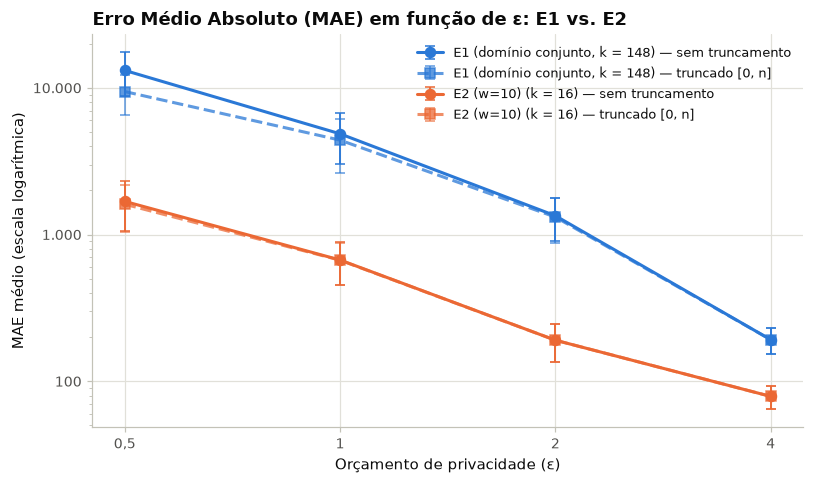

In [54]:
linhas_91 = []
linhas_91_fmt = []

for eps in EPSILONS:
    r1 = resumo.loc[("E1", eps)]
    r2 = resumo.loc[(NOME_E2, eps)]
    
    linhas_91.append({
        "estrategia": "E1", "epsilon": eps,
        "mae": r1["mae"], "dp": r1["dp"],
        "mae_trunc": r1["mae_trunc"], "dp_trunc": r1["dp_trunc"]
    })
    linhas_91.append({
        "estrategia": NOME_E2, "epsilon": eps,
        "mae": r2["mae"], "dp": r2["dp"],
        "mae_trunc": r2["mae_trunc"], "dp_trunc": r2["dp_trunc"]
    })
    
    linhas_91_fmt.append({
        "ε": fmt_eps(eps),
        "E1 (sem trunc.)": fmt_media_dp(r1["mae"], r1["dp"]),
        "E1 (trunc. [0, n])": fmt_media_dp(r1["mae_trunc"], r1["dp_trunc"]),
        f"{NOME_E2} (sem trunc.)": fmt_media_dp(r2["mae"], r2["dp"]),
        f"{NOME_E2} (trunc. [0, n])": fmt_media_dp(r2["mae_trunc"], r2["dp_trunc"]),
        "Razão E1 ÷ E2": f"{r1['mae'] / r2['mae']:.1f}×".replace(".", ",")
    })

tab06_dados = pd.DataFrame(linhas_91)
tab06_fmt = pd.DataFrame(linhas_91_fmt).set_index("ε")
salvar_tabela("tab06_mae_E1_E2", tab06_dados, tab06_fmt)
display(tab06_fmt)

# 2. Figura fig03_mae_vs_eps
fig, ax = plt.subplots(figsize=(7.5, 4.5))
x = np.arange(len(EPSILONS))

for est, cor, rotulo in [("E1", COR_E1, "E1 (domínio conjunto, k = 148)"),
                         (NOME_E2, COR_E2, f"{NOME_E2} (k = 16)")]:
    r = resumo.loc[est].reindex(EPSILONS)
    # Sem truncamento (linha sólida)
    ax.errorbar(x, r["mae"], yerr=r["dp"], color=cor, marker="o",
                capsize=3, elinewidth=1.2, zorder=3, label=f"{rotulo} — sem truncamento")
    # Com truncamento (linha tracejada)
    ax.errorbar(x, r["mae_trunc"], yerr=r["dp_trunc"], color=cor, marker="s",
                linestyle="--", alpha=0.75, capsize=3, elinewidth=1, zorder=2,
                label=f"{rotulo} — truncado [0, n]")

eixo_log(ax)
ax.set_xticks(x, [fmt_eps(e) for e in EPSILONS])
ax.set_xlabel("Orçamento de privacidade (ε)")
ax.set_ylabel("MAE médio (escala logarítmica)")
ax.set_title("Erro Médio Absoluto (MAE) em função de ε: E1 vs. E2", fontweight="bold")
ax.legend(loc="upper right", fontsize=8.5)
fig.tight_layout()
salvar_figura(fig, "fig03_mae_vs_eps")
plt.show()

**Leitura:** o E2 (w = 10) tem MAE menor em todos os ε: cerca de 7× a 8× menor para ε ≤ 2 e 2,4× menor para ε = 4. O truncamento só faz diferença visível no E1 com ε pequeno.

### 9.2 MAE por consulta · *Parte B*

**A implementar:** "um gráfico ou uma tabela com o MAE de cada consulta, para um valor fixo de ε" (Seção 6.2 do enunciado). Usar ε = 1 (`EPSILON_FIXO`).

* **Tabela `tab07_mae_por_consulta_eps1`:** CSV com as colunas `estrategia`, `epsilon`, `consulta`, `mae` e `dp`, para E1 e E2 (w=10) com ε = 1 (20 linhas). Versão formatada sugerida: uma linha por consulta, com o predicado, a resposta verdadeira, o MAE de cada estratégia e o erro relativo (MAE ÷ resposta verdadeira).
* **Figura `fig04_mae_por_consulta_eps1`:** MAE de Q1 a Q10 para E1 e E2 com ε = 1 (barras agrupadas ou pontos), com o eixo do MAE em escala logarítmica.
* *Opcional:* `fig05_mae_por_consulta_todos_eps`, com um painel por ε.

A tabela completa, com todas as estratégias e todos os ε, já está em `resultados/tabelas/mae_por_consulta_todas_estrategias.csv`.

,Predicado,Verdadeiro,MAE E1,Erro Rel. E1,MAE E2 (w=10),Erro Rel. E2 (w=10)
Consulta,,,,,,
Q1,30 ≤ Idade ≤ 50 ∧ Sal = >50K,7.820,"4.034,2 ± 3.875,2","51,6%","611,5 ± 408,5","7,8%"
Q2,Idade < 20 ∧ Sal = ≤50K,2.507,"2.838,8 ± 1.945,9","113,2%","557,1 ± 573,6","22,2%"
Q3,Idade ≥ 60 ∧ Sal = >50K,985,"4.769,4 ± 4.040,3","484,2%","590,4 ± 417,2","59,9%"
Q4,20 ≤ Idade ≤ 30 ∧ Sal = >50K,990,"3.674,3 ± 2.373,0","371,1%","414,6 ± 295,0","41,9%"
Q5,40 ≤ Idade ≤ 60 ∧ Sal = >50K,6.629,"5.114,7 ± 3.949,5","77,2%","558,2 ± 250,7","8,4%"
Q6,Idade ≤ 30 ∧ Sal = ≤50K,14.800,"3.868,7 ± 3.495,9","26,1%","831,1 ± 586,4","5,6%"
Q7,Idade ≥ 40 ∧ Sal = ≤50K,13.918,"6.766,0 ± 5.639,5","48,6%","816,7 ± 539,2","5,9%"
Q8,30 ≤ Idade ≤ 40 ∧ Sal = ≤50K,10.261,"3.189,1 ± 2.738,2","31,1%","490,3 ± 350,2","4,8%"
Q9,Idade ≥ 50,10.674,"5.488,7 ± 4.726,9","51,4%","731,8 ± 573,0","6,9%"


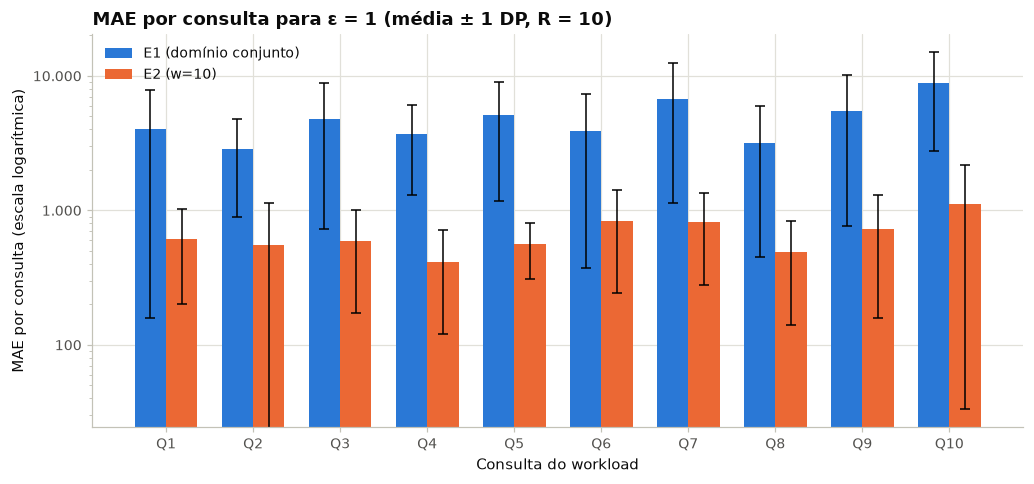

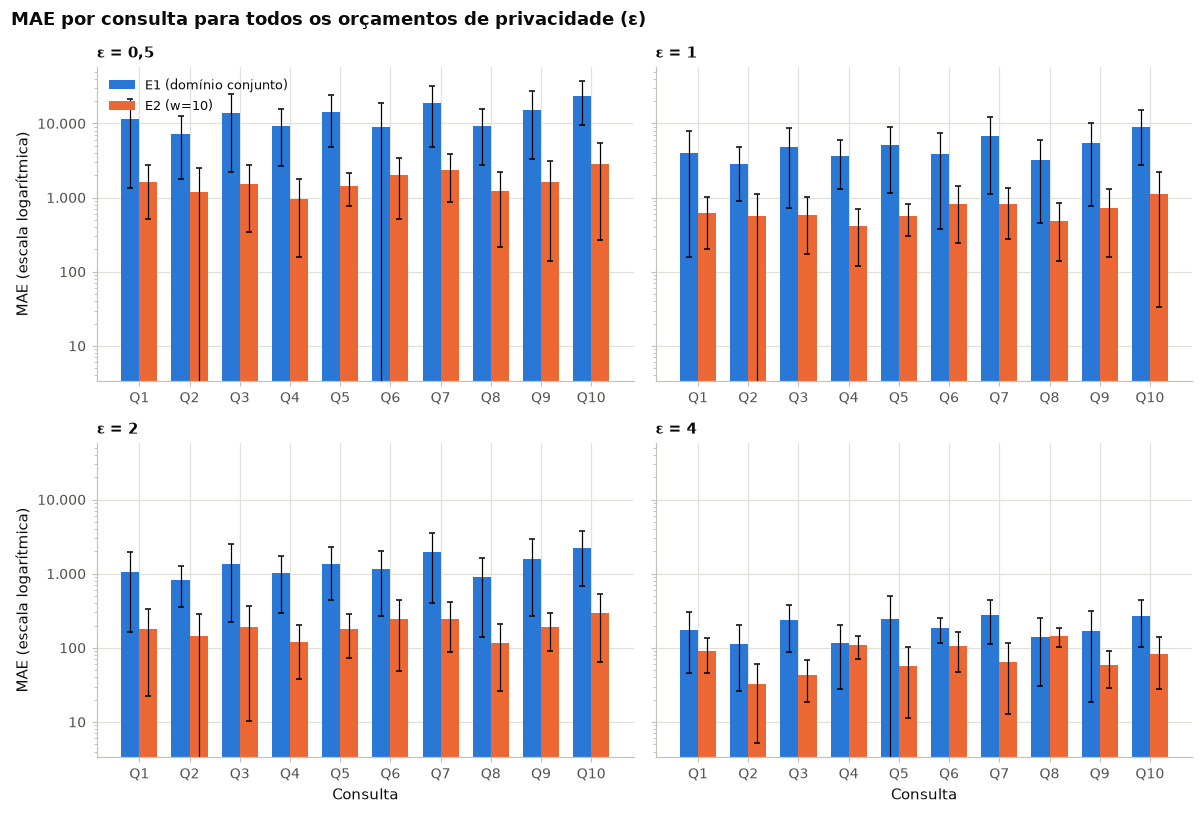

In [55]:
linhas_92 = []
linhas_92_fmt = []

pq_e1 = pq.loc[("E1", EPSILON_FIXO)].reindex(IDS_CONSULTAS)
pq_e2 = pq.loc[(NOME_E2, EPSILON_FIXO)].reindex(IDS_CONSULTAS)

for q in IDS_CONSULTAS:
    for est, df_q in [("E1", pq_e1), (NOME_E2, pq_e2)]:
        linhas_92.append({
            "estrategia": est,
            "epsilon": EPSILON_FIXO,
            "consulta": q,
            "mae": df_q.loc[q, "mae"],
            "dp": df_q.loc[q, "dp"]
        })
        
    verd = pq_e1.loc[q, "verdadeiro"]
    m1, d1 = pq_e1.loc[q, "mae"], pq_e1.loc[q, "dp"]
    m2, d2 = pq_e2.loc[q, "mae"], pq_e2.loc[q, "dp"]
    
    linhas_92_fmt.append({
        "Consulta": q,
        "Predicado": tab_workload.loc[q, "predicado"],
        "Verdadeiro": fmt(verd, 0),
        "MAE E1": fmt_media_dp(m1, d1),
        "Erro Rel. E1": f"{(m1 / verd) * 100:.1f}%".replace(".", ","),
        f"MAE {NOME_E2}": fmt_media_dp(m2, d2),
        f"Erro Rel. {NOME_E2}": f"{(m2 / verd) * 100:.1f}%".replace(".", ",")
    })

tab07_dados = pd.DataFrame(linhas_92)
tab07_fmt = pd.DataFrame(linhas_92_fmt).set_index("Consulta")
salvar_tabela("tab07_mae_por_consulta_eps1", tab07_dados, tab07_fmt)
display(tab07_fmt)

# 2. Figura fig04_mae_por_consulta_eps1
fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(IDS_CONSULTAS))
largura = 0.36

ax.bar(x - largura/2, pq_e1["mae"], yerr=pq_e1["dp"], width=largura,
       color=COR_E1, capsize=3, error_kw={"elinewidth": 1}, label="E1 (domínio conjunto)")
ax.bar(x + largura/2, pq_e2["mae"], yerr=pq_e2["dp"], width=largura,
       color=COR_E2, capsize=3, error_kw={"elinewidth": 1}, label=f"{NOME_E2}")

eixo_log(ax)
ax.set_xticks(x, IDS_CONSULTAS)
ax.set_xlabel("Consulta do workload")
ax.set_ylabel("MAE por consulta (escala logarítmica)")
ax.set_title(f"MAE por consulta para ε = {fmt_eps(EPSILON_FIXO)} (média ± 1 DP, R = 10)", fontweight="bold")
ax.legend(loc="upper left")
fig.tight_layout()
salvar_figura(fig, "fig04_mae_por_consulta_eps1")
plt.show()

# fig05_mae_por_consulta_todos_eps (um painel por ε)
fig, eixos = plt.subplots(2, 2, figsize=(11, 7.5), sharey=True)
x = np.arange(len(IDS_CONSULTAS))
largura = 0.36

for ax, eps in zip(eixos.flat, EPSILONS):
    pq_e1_eps = pq.loc[("E1", eps)].reindex(IDS_CONSULTAS)
    pq_e2_eps = pq.loc[(NOME_E2, eps)].reindex(IDS_CONSULTAS)
    
    ax.bar(x - largura/2, pq_e1_eps["mae"], yerr=pq_e1_eps["dp"], width=largura,
           color=COR_E1, capsize=2, error_kw={"elinewidth": 0.8}, label="E1 (domínio conjunto)")
    ax.bar(x + largura/2, pq_e2_eps["mae"], yerr=pq_e2_eps["dp"], width=largura,
           color=COR_E2, capsize=2, error_kw={"elinewidth": 0.8}, label=f"{NOME_E2}")
    
    ax.set_title(f"ε = {fmt_eps(eps)}", fontsize=10, fontweight="bold")
    ax.set_xticks(x, IDS_CONSULTAS)
    if ax in eixos[1]:
        ax.set_xlabel("Consulta")

eixo_log(eixos[0, 0])
eixos[0, 0].set_ylabel("MAE (escala logarítmica)")
eixos[1, 0].set_ylabel("MAE (escala logarítmica)")
eixos[0, 0].legend(loc="upper left", fontsize=8.5)
fig.suptitle("MAE por consulta para todos os orçamentos de privacidade (ε)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar_figura(fig, "fig05_mae_por_consulta_todos_eps")
plt.show()

### 9.3 E2: comparação entre larguras de bin · *Parte B*

**A implementar:** "para E2, uma comparação do MAE entre os tamanhos de bin avaliados" (Seção 6.2 do enunciado).

* **Tabela `tab08_larguras_bin`:** CSV com as colunas `estrategia`, `epsilon`, `mae` e `dp`, para as 6 configurações de `CONFIGS_LARGURA` nos 4 ε (24 linhas). Pode incluir também as variantes "início 17" e E2\* (`CONFIGS_TABELA`). Versão formatada sugerida: uma linha por estratégia, com k e consultas exatas (`tab_candidatas`) e "média ± dp" para cada ε.
* **Figura `fig06_larguras_bin`:** MAE × largura do bin (1 = E1, 2, 5, 10, 15, 20), **uma curva por ε** (cores `RAMPA_EPS[eps]`), eixo vertical em escala logarítmica, destacando w = 10 (a escolha) e, se possível, a melhor largura de cada ε.

,k,Exatas,"ε = 0,5",ε = 1,ε = 2,ε = 4
Estratégia,,,,,,
E1,148,10,"13.163,3 ± 4.402,3","4.866,1 ± 1.829,7","1.344,6 ± 437,8","192,2 ± 38,0"
E2 (w=2),74,5,"6.044,8 ± 1.414,8","2.431,5 ± 608,6","712,1 ± 230,5","128,7 ± 20,3"
E2 (w=5),30,5,"2.387,6 ± 551,9","941,6 ± 262,5","301,4 ± 93,4","68,4 ± 20,5"
E2 (w=10),16,5,"1.684,7 ± 624,1","671,4 ± 215,5","190,7 ± 54,4","78,9 ± 14,5"
E2 (w=15),10,2,"957,4 ± 310,0","644,6 ± 100,4","477,9 ± 40,7","416,1 ± 13,7"
E2 (w=20),10,4,"1.385,0 ± 343,6","1.011,1 ± 152,3","800,3 ± 63,4","728,7 ± 7,8"
"E2 (w=5, início 17)",30,1,"2.210,6 ± 404,0","894,2 ± 181,9","307,4 ± 65,1","107,7 ± 20,9"
"E2 (w=10, início 17)",16,1,"1.480,4 ± 767,5","616,4 ± 296,1","317,2 ± 77,4","296,6 ± 23,6"
"E2 (w=20, início 17)",8,1,"985,1 ± 311,4","762,7 ± 111,9","712,4 ± 72,1","694,3 ± 10,4"


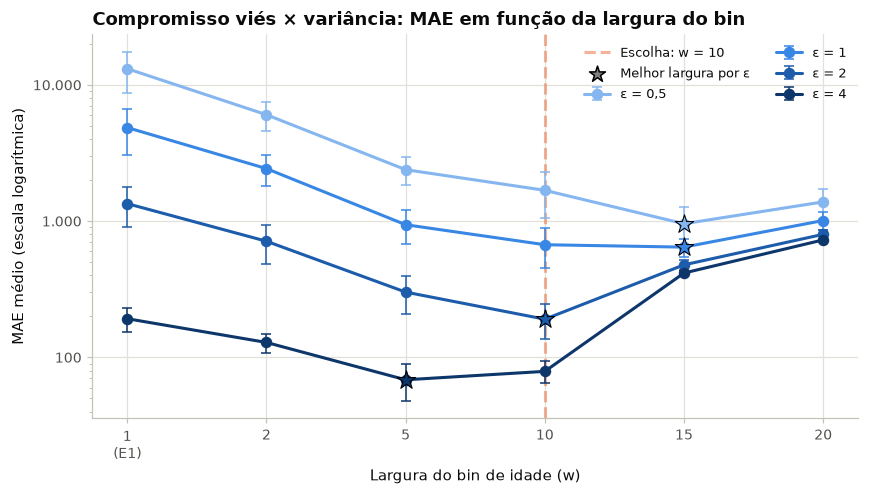

In [56]:
linhas_93 = []
for cfg in CONFIGS_LARGURA:
    for eps in EPSILONS:
        r = resumo.loc[(cfg, eps)]
        linhas_93.append({
            "estrategia": cfg,
            "epsilon": eps,
            "mae": r["mae"],
            "dp": r["dp"]
        })

tab08_dados = pd.DataFrame(linhas_93)

linhas_93_fmt = []
for cfg in CONFIGS_TABELA:
    linha = {
        "Estratégia": cfg,
        "k": tab_candidatas.loc[cfg, "k"],
        "Exatas": tab_candidatas.loc[cfg, "consultas exatas"]
    }
    for eps in EPSILONS:
        r = resumo.loc[(cfg, eps)]
        linha[f"ε = {fmt_eps(eps)}"] = fmt_media_dp(r["mae"], r["dp"])
    linhas_93_fmt.append(linha)

tab08_fmt = pd.DataFrame(linhas_93_fmt).set_index("Estratégia")
salvar_tabela("tab08_larguras_bin", tab08_dados, tab08_fmt)
display(tab08_fmt)

# 2. Figura fig06_larguras_bin (MAE x largura do bin: 1 = E1, 2, 5, 10, 15, 20)
fig, ax = plt.subplots(figsize=(8.0, 4.6))
larguras_plot = [1] + list(LARGURAS)
x = np.arange(len(larguras_plot))

for eps in EPSILONS:
    maes = [resumo.loc[(cfg, eps), "mae"] for cfg in CONFIGS_LARGURA]
    dps = [resumo.loc[(cfg, eps), "dp"] for cfg in CONFIGS_LARGURA]
    
    ax.errorbar(x, maes, yerr=dps, color=RAMPA_EPS[eps], marker="o",
                capsize=3, elinewidth=1, zorder=3, label=f"ε = {fmt_eps(eps)}")
    
    # Destaca com estrela o menor MAE de cada epsilon
    idx_min = int(np.argmin(maes))
    ax.scatter(x[idx_min], maes[idx_min], color=RAMPA_EPS[eps], marker="*",
               s=160, edgecolor="black", linewidth=0.7, zorder=5)

# Destaca a largura escolhida (w = 10) com faixa vertical suave
idx_w10 = larguras_plot.index(10)
ax.axvline(x[idx_w10], color=COR_E2, linestyle="--", alpha=0.5, zorder=1, label="Escolha: w = 10")
ax.scatter([], [], color="gray", marker="*", s=120, edgecolor="black", label="Melhor largura por ε")

eixo_log(ax)
rotulos_x = ["1\n(E1)"] + [str(w) for w in LARGURAS]
ax.set_xticks(x, rotulos_x)
ax.set_xlabel("Largura do bin de idade (w)")
ax.set_ylabel("MAE médio (escala logarítmica)")
ax.set_title("Compromisso viés × variância: MAE em função da largura do bin", fontweight="bold")
ax.legend(loc="upper right", ncol=2, fontsize=8.5)
fig.tight_layout()
salvar_figura(fig, "fig06_larguras_bin")
plt.show()

**Leitura:** as curvas de MAE × largura têm forma de U, a cara do compromisso viés × variância. Com ε pequeno o ruído domina e a melhor largura é grande (w = 15). Conforme ε cresce, o viés passa a dominar e o mínimo se desloca para larguras menores e alinhadas: w = 10 em ε = 2, w = 5 ≈ w = 10 em ε = 4. A largura w = 10 nunca fica longe do mínimo (Seção 10).

#### Conferência da Parte B

Esta célula não precisa ser editada. Ela confere se os arquivos das Seções 9.1 a 9.3 existem e se os números das tabelas batem com os do protocolo, e mostra "pendente" no que ainda não foi feito.

In [57]:
def conferir_parte_b() -> None:
    """Confere os arquivos da Parte B (Seções 9.1–9.3) contra os resultados do protocolo. Só lê arquivos."""
    def conferir_tabela(nome: str, chaves: tuple[str, ...], exigidas: set, referencia) -> str:
        caminho = DIR_TABELAS / f"{nome}.csv"
        if not caminho.exists():
            return f"pendente  {caminho}"
        try:
            tabela = pd.read_csv(caminho)
            if not {*chaves, "mae"} <= set(tabela.columns):
                return f"✗  {caminho}: o CSV precisa das colunas {[*chaves, 'mae']} (formato longo)"
            mae = pd.to_numeric(tabela["mae"], errors="coerce")          # texto como "1.234,5" vira NaN
            valores = dict(zip(tabela[list(chaves)].itertuples(index=False, name=None), mae))
            faltando = [k for k in exigidas if k not in valores]
            divergentes = [k for k in exigidas if k in valores and not abs(valores[k] - referencia(k)) <= 0.05]
        except Exception as erro:                                          # nunca interrompe o "Run All"
            return f"✗  {caminho}: não foi possível conferir ({erro})"
        if faltando or divergentes:
            return (f"✗  {caminho}: {len(faltando)} linha(s) faltando, {len(divergentes)} valor(es) divergente(s) "
                    "(a coluna mae deve ter os números sem formatação)")
        return f"✓  {caminho}"

    print(conferir_tabela("tab06_mae_E1_E2", ("estrategia", "epsilon"),
                          {(e, eps) for e in ("E1", NOME_E2) for eps in EPSILONS}, lambda k: resumo.loc[k, "mae"]))
    print(conferir_tabela("tab07_mae_por_consulta_eps1", ("estrategia", "epsilon", "consulta"),
                          {(e, EPSILON_FIXO, q) for e in ("E1", NOME_E2) for q in IDS_CONSULTAS},
                          lambda k: pq.loc[k, "mae"]))
    print(conferir_tabela("tab08_larguras_bin", ("estrategia", "epsilon"),
                          {(c, eps) for c in CONFIGS_LARGURA for eps in EPSILONS}, lambda k: resumo.loc[k, "mae"]))
    for figura in ("fig03_mae_vs_eps", "fig04_mae_por_consulta_eps1", "fig06_larguras_bin"):
        caminho = DIR_FIGURAS / f"{figura}.png"
        print(("✓  " if caminho.exists() else "pendente  ") + str(caminho))


conferir_parte_b()

✓  resultados\tabelas\tab06_mae_E1_E2.csv
✓  resultados\tabelas\tab07_mae_por_consulta_eps1.csv
✓  resultados\tabelas\tab08_larguras_bin.csv
✓  resultados\figuras\fig03_mae_vs_eps.png
✓  resultados\figuras\fig04_mae_por_consulta_eps1.png
✓  resultados\figuras\fig06_larguras_bin.png


### 9.4 Efeito do alinhamento da grade

Mesma largura, grades diferentes: múltiplos de w (alinhada às dezenas quando w divide 10) × grade iniciando em 17.

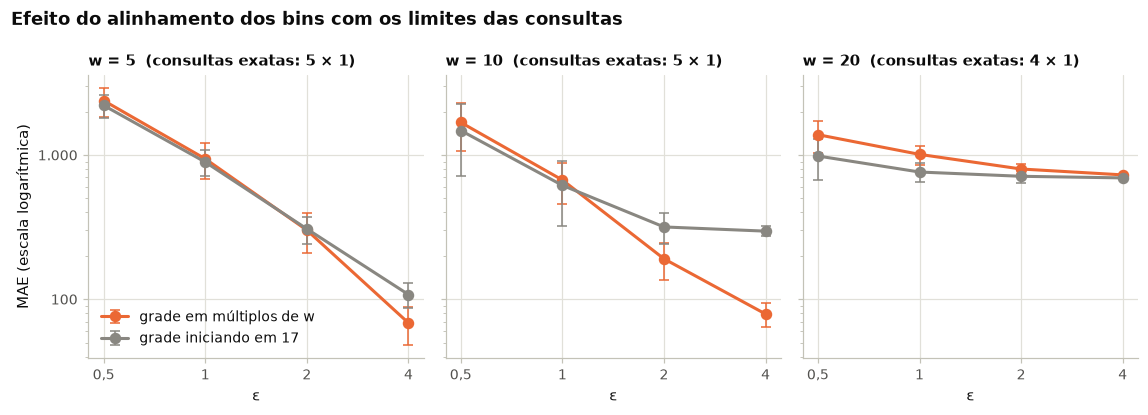

In [58]:
fig, eixos = plt.subplots(1, 3, figsize=(10.5, 3.8), sharey=True)
x = np.arange(len(EPSILONS))
for ax, w in zip(eixos, (5, 10, 20)):
    for nome, cor, rotulo in [(f"E2 (w={w})", COR_E2, "grade em múltiplos de w"),
                              (f"E2 (w={w}, início 17)", COR_NEUTRA, "grade iniciando em 17")]:
        r = resumo.loc[nome].reindex(EPSILONS)
        ax.errorbar(x, r["mae"], yerr=r["dp"], color=cor, marker="o", capsize=3, elinewidth=1, zorder=3, label=rotulo)
    exatas = tab_candidatas.loc[f"E2 (w={w})", "consultas exatas"], tab_candidatas.loc[f"E2 (w={w}, início 17)", "consultas exatas"]
    ax.set_title(f"w = {w}  (consultas exatas: {exatas[0]} × {exatas[1]})", fontsize=10)
    ax.set_xticks(x, [fmt_eps(e) for e in EPSILONS])
    ax.set_xlabel("ε")
eixo_log(eixos[0])
eixos[0].set_ylabel("MAE (escala logarítmica)")
eixos[0].legend(loc="lower left")
fig.suptitle("Efeito do alinhamento dos bins com os limites das consultas", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar_figura(fig, "fig07_alinhamento")
plt.show()

**Leitura:** com ε ≤ 1 o alinhamento quase não importa, porque o ruído domina. Com ε alto, a grade iniciando em 17 é bem pior para w = 5 e w = 10. Com w = 10, o MAE em ε = 4 sobe de 79 para 297, pois 9 das 10 consultas atravessam bins, com frações de até 7/10. Para w = 20, nenhuma das duas grades acompanha todas as dezenas (os bins de 20 anos são cortados ao meio em 30 e 50) e ambas são ruins.

### 9.5 Viés × ruído por consulta no E2 (w = 10)

Erro de cada consulta decomposto em **ruído** (o erro absoluto esperado se não houvesse viés, $\sigma\sqrt{2/\pi}$) e **viés** de discretização, que só existe nas consultas que atravessam um bin. Losangos: MAE empírico (R = 10).

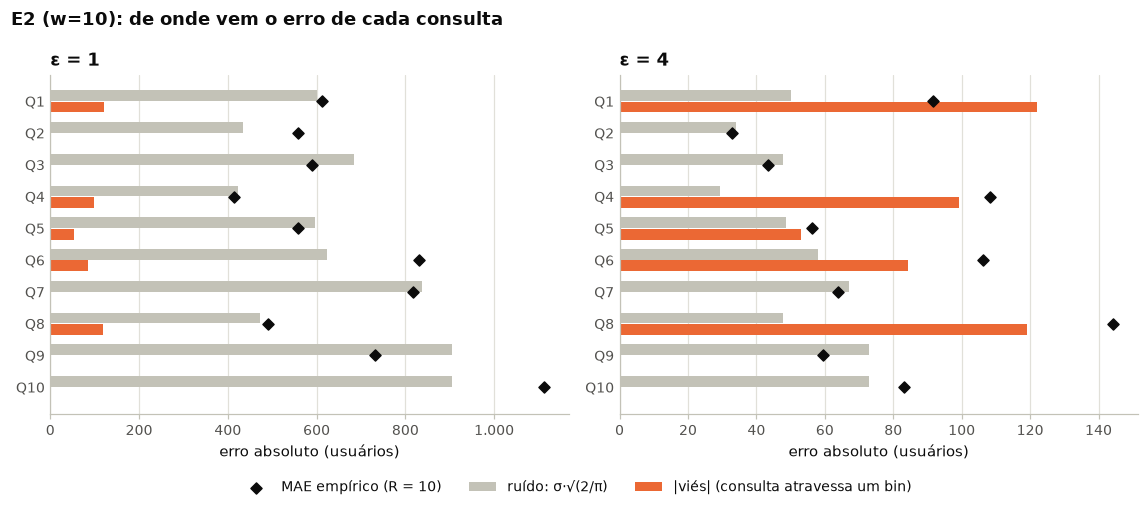

Viés (não depende de ε) e ruído esperado σ·√(2/π) de cada consulta, em número de usuários:


,viés E2 (w=10),"viés E2 (w=10, início 17)","ruído E2 (w=10), ε = 0,5","ruído E2 (w=10), ε = 1","ruído E2 (w=10), ε = 2","ruído E2 (w=10), ε = 4"
consulta,,,,,,
Q1,"-122,1","-565,0","1.494,1","600,8","199,0","50,0"
Q2,"0,0","650,8","1.091,2","434,8","140,7","34,0"
Q3,"0,0","205,0","1.742,1","684,6","212,8","47,7"
Q4,"99,1","265,4","1.078,4","423,6","131,5","29,4"
Q5,"-53,1","-204,0","1.490,5","597,4","196,3","48,7"
Q6,"-84,2","-186,0","1.517,8","622,8","216,5","58,0"
Q7,"0,0","231,7","2.094,1","837,0","273,0","67,0"
Q8,"-119,2","-94,6","1.131,7","473,3","171,1","47,9"
Q9,"0,0","444,1","2.261,0","904,9","296,1","73,0"


In [59]:
def coluna_teoria(nome_estrategia: str, eps: float, campo: str) -> pd.Series:
    """Uma coluna do erro teórico (viés, dp_ruido, ruido_esperado, erro_esperado) indexada pela consulta."""
    sel = teoria[(teoria["estrategia"] == nome_estrategia) & (teoria["epsilon"] == eps)]
    return sel.set_index("consulta")[campo].reindex(IDS_CONSULTAS)


fig, eixos = plt.subplots(1, 2, figsize=(10.5, 4.6))
for ax, eps in zip(eixos, (1.0, 4.0)):
    empirico = pq.loc[(NOME_E2, eps)]["mae"].reindex(IDS_CONSULTAS)
    ys = np.arange(len(IDS_CONSULTAS))[::-1]
    ax.barh(ys + 0.18, coluna_teoria(NOME_E2, eps, "ruido_esperado"), height=0.34, color=COR_NEUTRA_CLARA,
            label="ruído: σ·√(2/π)", zorder=2)
    ax.barh(ys - 0.18, coluna_teoria(NOME_E2, eps, "vies").abs(), height=0.34, color=COR_E2,
            label="|viés| (consulta atravessa um bin)", zorder=2)
    ax.scatter(empirico, ys, marker="D", s=26, color="#0b0b0b", zorder=4, label="MAE empírico (R = 10)")
    ax.set_yticks(ys, IDS_CONSULTAS)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(EIXO_BR)
    ax.set_title(f"ε = {fmt_eps(eps)}")
    ax.set_xlabel("erro absoluto (usuários)")
fig.legend(*eixos[0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
fig.suptitle("E2 (w=10): de onde vem o erro de cada consulta", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(rect=(0, 0.06, 1, 1))
salvar_figura(fig, "fig08_vies_ruido_E2")
plt.show()

tab_vies = pd.DataFrame({
    "viés E2 (w=10)": coluna_teoria(NOME_E2, EPSILONS[0], "vies"),
    "viés E2 (w=10, início 17)": coluna_teoria("E2 (w=10, início 17)", EPSILONS[0], "vies"),
    **{f"ruído E2 (w=10), ε = {fmt_eps(e)}": coluna_teoria(NOME_E2, e, "ruido_esperado") for e in EPSILONS},
})
tab_vies.index.name = "consulta"
tab_vies_fmt = tab_vies.apply(lambda col: col.map(lambda v: fmt(v, 1)))
salvar_tabela("tab09_vies_ruido_E2", tab_vies, tab_vies_fmt)
print("Viés (não depende de ε) e ruído esperado σ·√(2/π) de cada consulta, em número de usuários:")
display(tab_vies_fmt)

**Leitura:** em ε = 1 o erro de todas as consultas é dominado pelo ruído, e o viés das cinco consultas que atravessam bins é pequeno em comparação. Em ε = 4 o ruído cai para 30–75 usuários, mas o viés continua o mesmo (até 122), e as consultas que atravessam bins viram as piores. Esse viés **não diminui com ε nem com mais repetições**, e é ele que limita o E2 quando ε cresce.

### 9.6 Efeito do truncamento em [0, n]

In [60]:
assert (resultados["erro_abs_trunc"] <= resultados["erro_abs"] + 1e-9).all()   # nunca piora uma consulta
fora = resultados.assign(truncada=(resultados["estimado"] < 0) | (resultados["estimado"] > N))
pct_truncadas = fora.groupby(["estrategia", "epsilon"])["truncada"].mean().mul(100).rename("% respostas truncadas")
tab_trunc = resumo.loc[["E1", NOME_E2], ["mae", "mae_trunc"]].join(pct_truncadas)
tab_trunc["redução do MAE (%)"] = 100 * (1 - tab_trunc["mae_trunc"] / tab_trunc["mae"])


def mae_truncando_celulas(estrategia: Estrategia, eps: float) -> float:
    """Alternativa NÃO adotada, só para comparação: limitar cada célula n̂_c a [0, n] ANTES de somar."""
    W = servidor_pesos_consultas(estrategia, WORKLOAD)
    maes = []
    for semente in SEMENTES:                                   # mesmas sementes → mesmos reports do protocolo
        reports = cliente_gerar_reports(estrategia, idades, salarios, eps, np.random.default_rng(semente))
        n_hat = np.clip(servidor_estimar_celulas(estrategia, reports, eps).ravel(), 0, len(reports))
        maes.append(np.mean(np.abs(W @ n_hat - Q_VERDADEIRO)))
    return float(np.mean(maes))


tab_trunc["mae_trunc_celulas"] = [mae_truncando_celulas(E1 if nome == "E1" else E2, eps) for nome, eps in tab_trunc.index]
tab_trunc_fmt = pd.DataFrame({
    "MAE sem truncamento": tab_trunc["mae"].map(fmt), "MAE truncando a resposta": tab_trunc["mae_trunc"].map(fmt),
    "% respostas truncadas": tab_trunc["% respostas truncadas"].map(lambda v: fmt(v, 1) + "%"),
    "redução do MAE": tab_trunc["redução do MAE (%)"].map(lambda v: fmt(v, 1) + "%"),
    "MAE truncando cada célula (não adotado)": tab_trunc["mae_trunc_celulas"].map(fmt),
})
tab_trunc_fmt.index = [f"{e}, ε = {fmt_eps(eps)}" for e, eps in tab_trunc.index]
tab_trunc_fmt.index.name = "configuração"
salvar_tabela("tab10_truncamento", tab_trunc, tab_trunc_fmt)
display(tab_trunc_fmt)

consultas_truncadas = (fora[fora["truncada"] & fora["estrategia"].isin(["E1", NOME_E2])]
                       .groupby(["estrategia", "consulta"]).size().rename("respostas truncadas"))
print("Consultas que mais caíram fora de [0, n] (em 40 execuções por estratégia):")
print(consultas_truncadas.sort_values(ascending=False).head(8).to_string())

,MAE sem truncamento,MAE truncando a resposta,% respostas truncadas,redução do MAE,MAE truncando cada célula (não adotado)
configuração,,,,,
"E1, ε = 0,5","13.163,3","9.446,3","39,0%","28,2%","48.405,9"
"E1, ε = 1","4.866,1","4.407,1","17,0%","9,4%","16.590,8"
"E1, ε = 2","1.344,6","1.317,1","5,0%","2,0%","3.473,6"
"E1, ε = 4","192,2","192,2","0,0%","0,0%","314,0"
"E2 (w=10), ε = 0,5","1.684,7","1.610,9","7,0%","4,4%","1.690,0"
"E2 (w=10), ε = 1","671,4","669,3","1,0%","0,3%","677,3"
"E2 (w=10), ε = 2","190,7","190,7","0,0%","0,0%","185,6"
"E2 (w=10), ε = 4","78,9","78,9","0,0%","0,0%","79,0"


Consultas que mais caíram fora de [0, n] (em 40 execuções por estratégia):
estrategia  consulta
E1          Q4          14
            Q3          10
            Q2           9
            Q10          8
            Q5           6
E2 (w=10)   Q3           5
E1          Q9           5
            Q7           4


**Leitura:** o truncamento é pós-processamento e nunca aumenta o erro de uma consulta. Ele ajuda bastante no E1 com ε pequeno, quando 39% das respostas caem fora de [0, n], e é irrelevante no E2 a partir de ε = 1. Nenhuma conclusão muda com ou sem truncamento. Truncamos a **resposta da consulta**, e não cada célula. A última coluna mostra por quê: zerar as células negativas antes de somar cria um viés positivo que se acumula nas consultas com muitas células. No E1 com ε = 0,5 isso deixa o MAE 3,7× **pior** do que sem truncamento.

### 9.7 Validação: MAE teórico × MAE empírico

Cada ponto é uma configuração (estratégia × ε) do protocolo. Se a implementação estiver correta, os pontos ficam sobre a diagonal, a menos da flutuação de usar só R = 10 repetições.

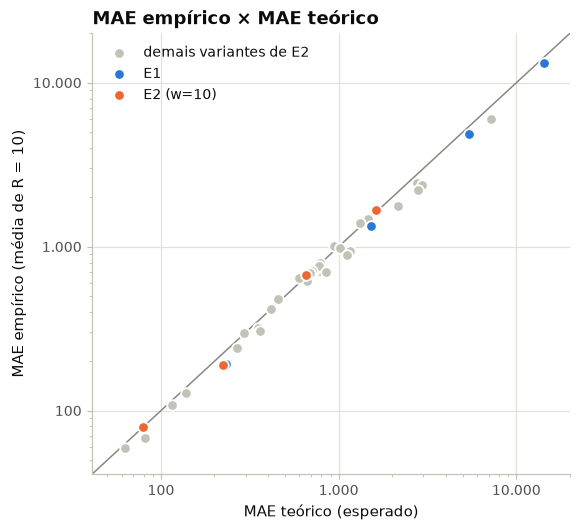

Razão empírico/teórico nas 40 configurações: mediana 0.924, intervalo [0.79, 1.08]


In [61]:
fig, ax = plt.subplots(figsize=(5.6, 5.2))
for grupo, cor, filtro in [("demais variantes de E2", COR_NEUTRA_CLARA, lambda e: e not in ("E1", NOME_E2)),
                           ("E1", COR_E1, lambda e: e == "E1"), (NOME_E2, COR_E2, lambda e: e == NOME_E2)]:
    sel = resumo[[filtro(e) for e in resumo.index.get_level_values("estrategia")]]
    ax.scatter(sel["mae_teorico"], sel["mae"], s=48, color=cor, edgecolor="white", linewidth=1.2, zorder=3, label=grupo)
limites = [resumo[["mae", "mae_teorico"]].min().min() * 0.7, resumo[["mae", "mae_teorico"]].max().max() * 1.4]
ax.plot(limites, limites, color=COR_NEUTRA, lw=1, zorder=1)
ax.set_xlim(limites)
ax.set_ylim(limites)
eixo_log(ax, "x")
eixo_log(ax, "y")
razao = resumo["mae"] / resumo["mae_teorico"]
ax.set_title("MAE empírico × MAE teórico")
ax.set_xlabel("MAE teórico (esperado)")
ax.set_ylabel("MAE empírico (média de R = 10)")
ax.legend(loc="upper left")
salvar_figura(fig, "fig09_teoria_vs_empirico")
plt.show()
print(f"Razão empírico/teórico nas {len(razao)} configurações: mediana {razao.median():.3f}, "
      f"intervalo [{razao.min():.2f}, {razao.max():.2f}]")

Com R = 10, o MAE empírico de cada configuração tem erro-padrão de cerca de 10% (desvio-padrão ≈ 30% da média, dividido por √10). Além disso, todas as configurações usam as mesmas 10 sementes, então os desvios em relação à teoria são correlacionados: os pontos ficam um pouco abaixo da diagonal de forma conjunta. Para separar a flutuação amostral de um eventual erro de implementação, repetimos E1 e E2 (w = 10) com **R = 1.000** e sementes 10.000–10.999, usadas só nesta validação:

In [62]:
SEMENTES_VALIDACAO = list(range(10_000, 11_000))            # R = 1.000, sementes usadas só nesta validação
inicio = time.perf_counter()
validacao = resumo_mae(executar_protocolo([E1, E2], EPSILONS, SEMENTES_VALIDACAO, WORKLOAD, idades, salarios))
validacao["mae_teorico"] = [mae_teorico(E1 if nome == "E1" else E2, eps) for nome, eps in validacao.index]
validacao["razao"] = validacao["mae"] / validacao["mae_teorico"]
validacao["erro_padrao"] = validacao["dp"] / math.sqrt(len(SEMENTES_VALIDACAO))
tab_validacao_fmt = pd.DataFrame({
    "MAE empírico (R = 1.000)": [f"{fmt(m)} (EP {fmt(ep)})" for m, ep in zip(validacao["mae"], validacao["erro_padrao"])],
    "MAE teórico": [fmt(v) for v in validacao["mae_teorico"]],
    "empírico ÷ teórico": [fmt(v, 3) for v in validacao["razao"]],
}, index=pd.Index([f"{nome}, ε = {fmt_eps(eps)}" for nome, eps in validacao.index], name="configuração"))
print(f"{len(SEMENTES_VALIDACAO) * len(validacao)} execuções em {time.perf_counter() - inicio:.1f} s "
      f"(EP = erro-padrão da média = desvio-padrão ÷ √R)")
salvar_tabela("tab11_validacao_teoria", validacao, tab_validacao_fmt)
display(tab_validacao_fmt)

8000 execuções em 29.4 s (EP = erro-padrão da média = desvio-padrão ÷ √R)


,MAE empírico (R = 1.000),MAE teórico,empírico ÷ teórico
configuração,,,
"E1, ε = 0,5","14.001,8 (EP 141,9)","14.291,7","0,980"
"E1, ε = 1","5.334,6 (EP 53,3)","5.438,7","0,981"
"E1, ε = 2","1.480,7 (EP 14,8)","1.512,0","0,979"
"E1, ε = 4","227,5 (EP 2,3)","230,9","0,985"
"E2 (w=10), ε = 0,5","1.605,4 (EP 16,3)","1.617,4","0,993"
"E2 (w=10), ε = 1","647,4 (EP 6,6)","651,4","0,994"
"E2 (w=10), ε = 2","223,9 (EP 2,1)","222,0","1,008"
"E2 (w=10), ε = 4","79,2 (EP 0,6)","79,7","0,994"


**Leitura:** com R = 1.000, o MAE empírico fica entre 0,98 e 1,01 do teórico nas 8 configurações, a no máximo cerca de 2 erros-padrão. Esses desvios são correlacionados entre os ε porque as sementes se repetem. Isso confirma a implementação do cliente, do servidor e do estimador, além da fórmula de variância usada na análise. O desvio maior visto com R = 10 (Fig. 9) é flutuação amostral.

### 9.8 Para além do protocolo: a melhor estratégia muda com ε?

Curvas: MAE teórico. Pontos: MAE empírico do experimento complementar (R = 10). A faixa sombreada é o intervalo de ε do protocolo.

Cruzamento E1 × E2 (w=10): ε ≈ 6.09


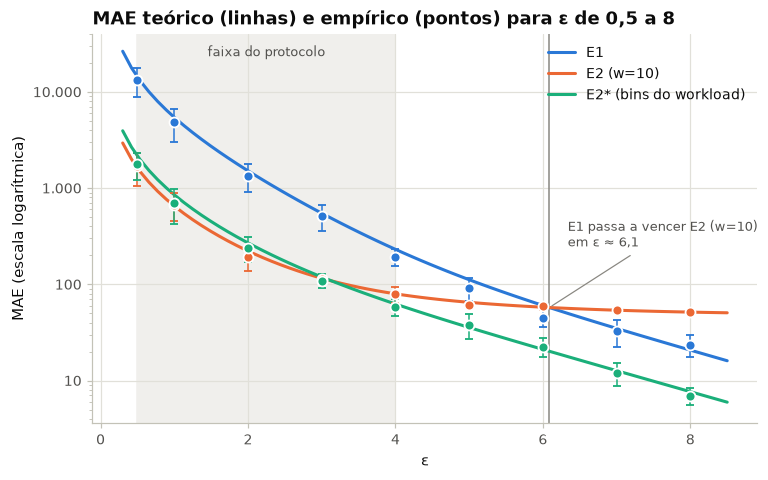

In [63]:
# ε em que o E1 passa a ser melhor que o E2 (w=10): bissecção no MAE teórico
baixo, alto = 4.0, 12.0
for _ in range(40):
    meio = (baixo + alto) / 2
    baixo, alto = (meio, alto) if mae_teorico(E1, meio) > mae_teorico(E2, meio) else (baixo, meio)
EPS_CRUZAMENTO = (baixo + alto) / 2
print(f"Cruzamento E1 × E2 (w=10): ε ≈ {EPS_CRUZAMENTO:.2f}")

grade_eps = np.linspace(0.3, 8.5, 70)
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.axvspan(0.5, 4.0, color=COR_FAIXA, zorder=0)
ax.text(2.25, 0.97, "faixa do protocolo", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8.5, color="#52514e")
for est, cor in [(E1, COR_E1), (E2, COR_E2), (E2_WORKLOAD, COR_E2_WORKLOAD)]:
    ax.plot(grade_eps, [mae_teorico(est, e) for e in grade_eps], color=cor, lw=2, zorder=2, label=f"{est.nome}")
    r = resumo_ext.loc[est.nome].reindex(EPSILONS_EXT)
    ax.errorbar(EPSILONS_EXT, r["mae"], yerr=r["dp"], fmt="o", color=cor, mec="white", mew=1.2, capsize=2.5,
                elinewidth=1, zorder=3)
ax.axvline(EPS_CRUZAMENTO, color=COR_NEUTRA, lw=1, zorder=1)
ax.annotate(f"E1 passa a vencer E2 (w=10)\nem ε ≈ {fmt(EPS_CRUZAMENTO, 1)}", (EPS_CRUZAMENTO, mae_teorico(E2, EPS_CRUZAMENTO)),
            xytext=(12, 40), textcoords="offset points", fontsize=8.5, color="#52514e",
            arrowprops=dict(arrowstyle="-", color=COR_NEUTRA, lw=0.8))
eixo_log(ax)
ax.set_xlabel("ε")
ax.set_ylabel("MAE (escala logarítmica)")
ax.set_title("MAE teórico (linhas) e empírico (pontos) para ε de 0,5 a 8")
ax.legend(loc="upper right")
salvar_figura(fig, "fig10_eps_estendido")
plt.show()

## 10. Análise: respostas às perguntas do enunciado

As tabelas abaixo são calculadas a partir dos resultados. O texto de cada resposta vem logo depois.

In [64]:
# Perguntas 1 e 2 — melhor estratégia em cada ε (E1 × E2) e se ela muda com ε
linhas = []
for eps in EPSILONS:
    m1, m2 = resumo.loc[("E1", eps), "mae"], resumo.loc[(NOME_E2, eps), "mae"]
    t1, t2 = resumo.loc[("E1", eps), "mae_trunc"], resumo.loc[(NOME_E2, eps), "mae_trunc"]
    linhas.append({"ε": fmt_eps(eps), "MAE E1": fmt(m1), "MAE E2 (w=10)": fmt(m2),
                   "melhor (sem trunc.)": "E2" if m2 < m1 else "E1", "melhor (truncado)": "E2" if t2 < t1 else "E1",
                   "E1 ÷ E2": fmt(m1 / m2, 1) + "×"})
tab_melhor = pd.DataFrame(linhas).set_index("ε")
salvar_tabela("tab12_melhor_estrategia", tab_melhor)
display(tab_melhor)

dp_q10 = {nome: coluna_teoria(nome, EPSILON_FIXO, "dp_ruido")["Q10"] for nome in ("E1", NOME_E2)}
print(f"Exemplo (Q10, ε = 1): desvio-padrão do ruído E1 = {fmt(dp_q10['E1'], 0)} × E2 = {fmt(dp_q10[NOME_E2], 0)} "
      f"→ {fmt(dp_q10['E1'] / dp_q10[NOME_E2], 1)}× menor no E2")
print(f"Fora do protocolo, o E1 só supera o E2 (w=10) para ε ≳ {fmt(EPS_CRUZAMENTO, 1)} (Seção 9.8).")

,MAE E1,MAE E2 (w=10),melhor (sem trunc.),melhor (truncado),E1 ÷ E2
ε,,,,,
"0,5","13.163,3","1.684,7",E2,E2,"7,8×"
1,"4.866,1","671,4",E2,E2,"7,2×"
2,"1.344,6","190,7",E2,E2,"7,1×"
4,"192,2","78,9",E2,E2,"2,4×"


Exemplo (Q10, ε = 1): desvio-padrão do ruído E1 = 9.628 × E2 = 1.134 → 8,5× menor no E2
Fora do protocolo, o E1 só supera o E2 (w=10) para ε ≳ 6,1 (Seção 9.8).


In [65]:
# Pergunta 3 — melhor largura em cada ε (empírico e teórico) e distância de cada largura para a melhor
teorico_w = pd.DataFrame({eps: [resumo.loc[(c, eps), "mae_teorico"] for c in CONFIGS_LARGURA] for eps in EPSILONS},
                         index=CONFIGS_LARGURA)
empirico_w = pd.DataFrame({eps: [resumo.loc[(c, eps), "mae"] for c in CONFIGS_LARGURA] for eps in EPSILONS},
                          index=CONFIGS_LARGURA)
razao_melhor = teorico_w / teorico_w.min()                      # 1,00× = a melhor largura naquele ε
tab_razao = razao_melhor.rename(columns=lambda e: f"ε = {fmt_eps(e)}")
tab_razao["pior caso"] = razao_melhor.max(axis=1)
tab_razao.index.name = "estratégia"
tab_razao_fmt = tab_razao.apply(lambda col: col.map(lambda v: fmt(v, 2) + "×"))
salvar_tabela("tab13_razao_para_melhor_largura", tab_razao, tab_razao_fmt)
print("MAE teórico de cada largura ÷ MAE da melhor largura no mesmo ε (1,00× = a melhor):")
display(tab_razao_fmt)
for eps in EPSILONS:
    print(f"ε = {fmt_eps(eps):>3}: melhor largura empírica = {empirico_w[eps].idxmin():10s} | teórica = {teorico_w[eps].idxmin()}")
print(f"Largura com o menor pior caso nos 4 ε: {tab_razao['pior caso'].idxmin()}")

MAE teórico de cada largura ÷ MAE da melhor largura no mesmo ε (1,00× = a melhor):


,"ε = 0,5",ε = 1,ε = 2,ε = 4,pior caso
estratégia,,,,,
E1,"13,57×","9,14×","6,81×","2,90×","13,57×"
E2 (w=2),"6,81×","4,62×","3,54×","1,73×","6,81×"
E2 (w=5),"2,80×","1,94×","1,59×","1,02×","2,80×"
E2 (w=10),"1,54×","1,09×","1,00×","1,00×","1,54×"
E2 (w=15),"1,00×","1,00×","2,05×","5,25×","5,25×"
E2 (w=20),"1,26×","1,58×","3,55×","9,19×","9,19×"


ε = 0,5: melhor largura empírica = E2 (w=15)  | teórica = E2 (w=15)
ε =   1: melhor largura empírica = E2 (w=15)  | teórica = E2 (w=15)
ε =   2: melhor largura empírica = E2 (w=10)  | teórica = E2 (w=10)
ε =   4: melhor largura empírica = E2 (w=5)   | teórica = E2 (w=10)
Largura com o menor pior caso nos 4 ε: E2 (w=10)


In [66]:
# Pergunta 4 — consultas respondidas com maior e menor precisão (MAE absoluto e erro relativo = MAE ÷ resposta)
linhas = []
for nome in ("E1", NOME_E2):
    for eps in EPSILONS:
        d = pq.loc[(nome, eps)].reindex(IDS_CONSULTAS)
        relativo = d["mae"] / d["verdadeiro"]
        linhas.append({"estratégia": nome, "ε": fmt_eps(eps),
                       "menor MAE": f"{d['mae'].idxmin()} ({fmt(d['mae'].min())})",
                       "maior MAE": f"{d['mae'].idxmax()} ({fmt(d['mae'].max())})",
                       "menor erro relativo": f"{relativo.idxmin()} ({fmt(100 * relativo.min())}%)",
                       "maior erro relativo": f"{relativo.idxmax()} ({fmt(100 * relativo.max())}%)"})
tab_extremos = pd.DataFrame(linhas).set_index(["estratégia", "ε"])
salvar_tabela("tab14_consultas_extremas", tab_extremos)
display(tab_extremos)

# O MAE de uma consulta cresce com o nº de células somadas? Correlação de Spearman (= Pearson dos postos)
celulas = {"E1": tab_alinhamento["células E1"], NOME_E2: tab_alinhamento["células E2 (w=10)"]}
tab_spearman = pd.DataFrame(
    {nome: [pq.loc[(nome, eps)]["mae"].reindex(IDS_CONSULTAS).rank().corr(celulas[nome].rank()) for eps in EPSILONS]
     for nome in ("E1", NOME_E2)},
    index=pd.Index([fmt_eps(e) for e in EPSILONS], name="ε"))
salvar_tabela("tab15_correlacao_celulas_mae", tab_spearman, tab_spearman.apply(lambda col: col.map(lambda v: fmt(v, 2))))
print("Correlação de Spearman entre o nº de células somadas pela consulta e o seu MAE:")
display(tab_spearman.apply(lambda col: col.map(lambda v: fmt(v, 2))))

mae_eps4 = pq.loc[(NOME_E2, 4.0)]["mae"].reindex(IDS_CONSULTAS)
print("E2 (w=10), ε = 4 — MAE por consulta:", " | ".join(f"{q} {fmt(v)}" for q, v in mae_eps4.items()))

menor MAE       maior MAE menor erro relativo  \
estratégia ε                                                       
E1         0,5  Q2 (7.263,0)  Q10 (23.411,6)          Q6 (60,8%)   
           1    Q2 (2.838,8)   Q10 (8.917,3)          Q6 (26,1%)   
           2      Q2 (815,0)   Q10 (2.218,6)           Q6 (7,8%)   
           4      Q2 (113,6)      Q7 (274,1)           Q6 (1,2%)   
E2 (w=10)  0,5    Q4 (960,6)   Q10 (2.881,4)          Q8 (12,0%)   
           1      Q4 (414,6)   Q10 (1.112,3)           Q8 (4,8%)   
           2      Q8 (117,0)     Q10 (295,5)           Q8 (1,1%)   
           4       Q2 (32,9)      Q8 (144,3)           Q7 (0,5%)   

               maior erro relativo  
estratégia ε                        
E1         0,5       Q3 (1.386,1%)  
           1           Q3 (484,2%)  
           2           Q3 (138,0%)  
           4            Q3 (24,0%)  
E2 (w=10)  0,5         Q3 (156,5%)  
           1            Q3 (59,9%)  
           2            Q3 (19,3%)  
           4            Q4 (10,9%)

Correlação de Spearman entre o nº de células somadas pela consulta e o seu MAE:


,E1,E2 (w=10)
ε,,
"0,5","0,90","0,87"
1,"0,94","0,82"
2,"0,94","0,86"
4,"0,69","-0,11"


E2 (w=10), ε = 4 — MAE por consulta: Q1 91,6 | Q2 32,9 | Q3 43,3 | Q4 108,3 | Q5 56,2 | Q6 106,2 | Q7 63,8 | Q8 144,3 | Q9 59,4 | Q10 83,2


### Respostas

#### 1. Qual estratégia apresenta o menor MAE para cada valor de ε?

O **E2 (w = 10)** tem o menor MAE nos quatro valores de ε, com e sem truncamento (Tabela 12, Fig. 3):

| ε | MAE E1 | MAE E2 (w = 10) | E1 ÷ E2 |
|---|---|---|---|
| 0,5 | 13.163 ± 4.402 | 1.685 ± 624 | 7,8× |
| 1 | 4.866 ± 1.830 | 671 ± 216 | 7,2× |
| 2 | 1.345 ± 438 | 191 ± 54 | 7,1× |
| 4 | 192 ± 38 | 79 ± 15 | 2,4× |

O motivo é o tamanho do domínio. Desprezando termos de ordem $n_S$, a variância do GRR para uma consulta que soma $|S|$ células de um domínio de tamanho $k$ é

$$\operatorname{Var}[\hat q_S]\;\approx\;\frac{n\,|S|\,\big(e^\varepsilon+k-1-|S|\big)}{(e^\varepsilon-1)^2}.$$

O ruído cresce com o tamanho do domínio $k$ e com o número de células somadas $|S|$. O E2 reduz os dois: $k$ cai de 148 para 16, e uma consulta passa a somar no máximo 8 células, contra até 82 no E1. Em Q10 com ε = 1, o desvio-padrão do ruído cai de 9.628 para 1.134 (8,5×). Intuitivamente, com ε = 1 só 1,8% dos usuários do E1 reportam a própria célula, contra 15,3% no E2.

#### 2. A melhor estratégia muda conforme ε?

**Na faixa do protocolo, não**: o E2 vence nos quatro ε. A vantagem, porém, **encolhe** de 7,8× para 2,4×, porque os erros das duas estratégias têm naturezas diferentes:

* o erro do **E1 é só ruído**, que cai rapidamente quando ε cresce;
* o erro do **E2 é ruído mais viés de discretização**. O viés aparece nas cinco consultas que atravessam um bin, vai de −122 a +99 usuários e **não depende de ε**. Em ε = 4 ele já domina o erro de Q1, Q4, Q6 e Q8 (Fig. 8).

O experimento complementar (Fig. 10) mostra a consequência: **o E1 passa a ser melhor que o E2 (w = 10) para ε ≳ 6,1**, quando o ruído do E1 fica menor que o viés do E2. A melhor *largura* do E2 também muda com ε (Fig. 6): w = 15 para ε ≤ 1, w = 10 para ε = 2 e w = 5 ≈ w = 10 para ε = 4.

#### 3. Qual tamanho de bin foi mais adequado ao workload em E2? Como a largura dos bins afeta a precisão, especialmente quando os limites de uma consulta atravessam um bin?

**w = 10, alinhado às dezenas** ([17–19], [20–29], …, [80–90]). A escolha veio do workload (Seção 7), cujos limites estão todos nas dezenas, e os experimentos a confirmam:

* é a melhor largura em ε = 2, fica a 9% da melhor em ε = 1 e empata com w = 5 em ε = 4 (MAE teórico 80 × 81; a diferença empírica 79 × 68 está dentro da flutuação de R = 10);
* tem o **menor pior caso**: nos quatro ε, fica no máximo 1,54× acima da melhor largura daquele ε, contra 2,80× para w = 5, 5,25× para w = 15 e 9,19× para w = 20 (Tabela 13).

A largura controla um compromisso **viés × variância**:

* **bins mais largos** reduzem k e o número de células por consulta, e portanto o **ruído**. Por isso w = 15 é o melhor para ε ≤ 1, quando o ruído domina;
* **bins mais largos** também pioram a hipótese de idades uniformes dentro do bin, o que aumenta o **viés** das consultas que atravessam bins. Por isso, com ε alto, só larguras pequenas e alinhadas (5 ou 10) funcionam, e w = 15 e w = 20 ficam 5× e 9× piores que a melhor.

**Quando o limite de uma consulta atravessa um bin**, o servidor soma a fração do bin correspondente às idades cobertas (1/10, no caso de w = 10). Como a distribuição real dentro do bin não é uniforme (Fig. 1), surge um viés sistemático (Tabela 9):

* Q4 (20–30 anos, >50K) recebe 1/10 do bin 30–39. Aos 30 anos há menos salários >50K do que na média da década de 30, então a consulta é superestimada em +99;
* Q1 (30–50 anos, >50K) recebe 1/10 do bin 50–59 e é subestimada em −122;
* Q8 (30–40 anos, ≤50K) recebe 1/10 do bin 40–49 e é subestimada em −119.

Esse viés não diminui com ε nem com mais repetições. O **alinhamento** importa tanto quanto a largura (Fig. 7): com a mesma largura 10, a grade iniciando em 17 faz 9 das 10 consultas atravessarem bins, com frações de até 7/10 e vieses de até 651 usuários, e o MAE em ε = 4 sobe de 79 para 297.

*Extra:* a partição não uniforme E2\*, com um corte em cada limite do workload, elimina o viés e é a melhor em ε = 4 (MAE 59). Em ε ≤ 2 ela perde para w = 10 porque tem mais bins e cada consulta soma mais células, o que traz mais ruído.

#### 4. Quais consultas são respondidas com maior e menor precisão por cada estratégia?

Em **erro absoluto** (a métrica do trabalho), o que decide é o número de células somadas (Tabelas 14 e 15):

* **E1:** a mais precisa é sempre **Q2** (3 células). As menos precisas são **Q10** (74 células, metade do domínio, onde $|S|(k-|S|)$ é máximo), **Q7** (51) e **Q9** (82). A correlação de Spearman entre número de células e MAE fica entre 0,90 e 0,94 para ε ≤ 2;
* **E2 (w = 10), ε ≤ 2:** mesma lógica (Spearman de 0,82 a 0,87). As mais precisas são as consultas de 1 ou 2 células (Q2, Q4, Q8); as menos precisas são **Q10** e Q9 (8 células) e Q7 (5);
* **E2 (w = 10), ε = 4:** a ordem muda (Spearman −0,11). As piores passam a ser as consultas **que atravessam bins**: Q8 (144), Q4 (108), Q6 (106) e Q1 (92). A melhor é **Q2** (33), que é exata e soma 1 célula.

Em **erro relativo** (MAE ÷ resposta verdadeira), as contagens pequenas são as mais prejudicadas, porque o ruído do LDP é aditivo e não depende do tamanho da resposta. **Q3** (985 pessoas) e **Q4** (990) têm os maiores erros relativos. No E1 com ε = 1, o erro de Q3 chega a 484% da resposta, o que a torna inútil; no E2, a 60%. As consultas grandes (Q6, Q7 e Q8, com 10 a 15 mil pessoas) ficam abaixo de 6% no E2 com ε = 1.

**Sobre o truncamento** (Seção 9.6): projetar as respostas em [0, n] nunca piora uma consulta e reduz o MAE do E1 em 28% com ε = 0,5. No E2 o ganho é pequeno (4,4% em ε = 0,5) e desaparece a partir de ε = 2. Nenhuma das respostas acima muda com ou sem truncamento.

### Conclusões

1. **Reduzir o domínio é a alavanca principal do GRR.** O ruído cresce com k e com o número de células somadas por consulta. Agrupar a idade em décadas (k de 148 para 16) reduz o MAE em 7 a 8× para ε ≤ 2.
2. **Bins trocam variância por viés.** O viés de discretização não diminui com ε. Por isso a vantagem do E2 cai de 7,8× para 2,4× entre ε = 0,5 e ε = 4, e o E1 venceria para ε ≳ 6.
3. **O melhor tamanho de bin depende de ε**: bins largos (15) quando o ruído domina, bins de 10 ou 5 quando o viés domina. **w = 10 alinhado às dezenas** é a melhor escolha única para esse workload, nunca mais que 1,54× pior que a melhor largura de cada ε.
4. **O alinhamento com os limites das consultas importa tanto quanto a largura**: a mesma largura 10 começando em 17 fica 3,8× pior em ε = 4. Se bins não uniformes forem permitidos, cortar exatamente nos limites do workload (E2\*) elimina o viés.
5. **Pós-processamento:** truncar a resposta em [0, n] só ajuda (até −28% no E1); truncar cada célula atrapalha muito (até 3,7× pior no E1).

## 11. Arquivos gerados

In [67]:
for arquivo in sorted(DIR_RESULTADOS.rglob("*")):
    if arquivo.is_file():
        print(f"{str(arquivo):70s} {arquivo.stat().st_size / 1024:7.1f} KB")

resultados\figuras\fig01_dados.pdf                                        25.7 KB
resultados\figuras\fig01_dados.png                                        45.5 KB
resultados\figuras\fig02_mapa_workload_bins.pdf                           28.5 KB
resultados\figuras\fig02_mapa_workload_bins.png                          125.1 KB
resultados\figuras\fig03_mae_vs_eps.pdf                                   31.4 KB
resultados\figuras\fig03_mae_vs_eps.png                                  116.4 KB
resultados\figuras\fig04_mae_por_consulta_eps1.pdf                        29.2 KB
resultados\figuras\fig04_mae_por_consulta_eps1.png                        58.2 KB
resultados\figuras\fig05_mae_por_consulta_todos_eps.pdf                   38.3 KB
resultados\figuras\fig05_mae_por_consulta_todos_eps.png                  117.6 KB
resultados\figuras\fig06_larguras_bin.pdf                                 30.6 KB
resultados\figuras\fig06_larguras_bin.png                                125.4 KB
resultados\figur